In [ ]:
# Cell 1: install dependencies
# Installs every dependency used by the notebook and the Streamlit app (run once)
!pip install -q streamlit pyngrok plotly kagglehub scikit-learn seaborn joblib
print("Dependencies installed.")

Dependencies installed.


# 💰 Personal Finance Analytics & Intelligent Expense Prediction Dashboard

## Section 0: Title, objective, tech stack and workflow

**Objective:** build an end-to-end analytics system that cleans household transaction data, stores it in SQL, explores spending behaviour, detects unusual expenses (Isolation Forest), predicts future expenses (regression) and serves everything through a Streamlit dashboard that non-technical users can use without writing code.

**How to run:** `Runtime → Run all`. The only manual step is uploading `kaggle.json`, and only if the automatic `kagglehub` download fails. An optional ngrok token is needed only to open the dashboard through ngrok (a localtunnel fallback needs nothing).

| Layer | Tool | Used for |
|---|---|---|
| Language | Python 3 | Everything |
| Data wrangling | Pandas, NumPy | Cleaning, EDA, feature engineering |
| Database | SQLite (`sqlite3`) | Transaction storage, queries, dashboard data retrieval |
| Machine learning | Scikit-learn | Isolation Forest, Linear / Ridge / Random Forest / Gradient Boosting regression |
| Static charts | Matplotlib, Seaborn | EDA and insight charts |
| Interactive charts | Plotly | Hover, filters, drill-down |
| App | Streamlit (+ pyngrok / localtunnel) | No-code interface for non-technical users |

**Workflow**

`Download data → Clean → Engineer features → Store in SQLite → SQL analysis → EDA → Budget utilization → Anomaly detection → Expense prediction → Plotly → Streamlit app → Evaluation → Packaging`

## Section 1: Setup and data loading

We import libraries, fix random seeds, then download the **Daily Household Transactions** dataset (`heeraldedhia/daily-household-transactions`).

- **Option A (kagglehub):** tried first, no setup needed for most public datasets.
- **Option B (Kaggle API):** if Option A fails, a file picker asks for your `kaggle.json` (Kaggle → Settings → API → *Create New Token*).
- **Last resort:** if both fail, a clearly labelled **synthetic** dataset with the same columns is generated so the notebook still runs end to end. Results from synthetic data are not real findings, and the notebook prints a warning when this happens.

Expected columns in the real file: `Date, Mode, Category, Subcategory, Note, Amount, Income/Expense, Currency`. If you use a different Kaggle finance dataset, only the `mapping` dictionary in the cleaning step needs adjusting.

In [ ]:
# Cell 4: imports, seeds, configuration
import os, re, json, glob, shutil, sqlite3, warnings, zipfile, subprocess, time
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from IPython.display import display, Markdown
from sklearn.preprocessing import LabelEncoder, StandardScaler

warnings.filterwarnings("ignore")
np.random.seed(42)
RANDOM_STATE = 42

# Output folders used by every later section
BASE_DIR = "/content" if os.path.isdir("/content") else os.getcwd()
os.chdir(BASE_DIR)
OUT_DIR = os.path.join(BASE_DIR, "outputs")
CHART_DIR = os.path.join(OUT_DIR, "charts")
for d in (OUT_DIR, CHART_DIR):
    os.makedirs(d, exist_ok=True)

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (11, 5)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)
print("Libraries loaded. Seeds set to 42. Output folder:", OUT_DIR)

Libraries loaded. Seeds set to 42. Output folder: /content/outputs


In [ ]:
# Cell 5: download the dataset
# Dataset download: Option A (kagglehub), Option B (Kaggle API + kaggle.json), then a labelled fallback
DATASET_SLUG = "heeraldedhia/daily-household-transactions"
DATA_DIR = os.path.join(BASE_DIR, "data")
os.makedirs(DATA_DIR, exist_ok=True)


def download_with_kagglehub(slug: str) -> str:
    """Option A: download via kagglehub and return the local folder path."""
    import kagglehub
    return kagglehub.dataset_download(slug)


def download_with_kaggle_api(slug: str, target: str) -> str:
    """Option B: download via the Kaggle CLI. Asks the user to upload kaggle.json if needed."""
    cfg = os.path.expanduser("~/.kaggle/kaggle.json")
    if not os.path.exists(cfg):
        from google.colab import files  # only exists on Colab
        print("Upload your kaggle.json now (Kaggle > Settings > API > Create New Token).")
        uploaded = files.upload()
        if "kaggle.json" not in uploaded:
            raise FileNotFoundError("kaggle.json was not uploaded.")
        os.makedirs(os.path.dirname(cfg), exist_ok=True)
        shutil.move("kaggle.json", cfg)
        os.chmod(cfg, 0o600)
    subprocess.run(["pip", "install", "-q", "kaggle"], check=True)
    subprocess.run(["kaggle", "datasets", "download", "-d", slug, "-p", target, "--unzip"], check=True)
    return target


def make_synthetic_dataset(n_months: int = 30) -> pd.DataFrame:
    """FALLBACK ONLY: builds a household-style dataset with the same columns as the Kaggle file."""
    rng = np.random.default_rng(42)
    rows = []
    cats = {"Food": (250, 120), "Transportation": (120, 60), "Household": (400, 200),
            "Health": (300, 150), "Entertainment": (350, 200), "Shopping": (500, 300),
            "Bills & Utilities": (600, 150), "Education": (700, 300)}
    modes = ["Cash", "Credit Card", "Debit Card", "UPI", "Saving Bank account 1"]
    start = pd.Timestamp("2022-01-01")
    for m in range(n_months):
        month_start = start + pd.DateOffset(months=m)
        rows.append([month_start + pd.Timedelta(days=int(rng.integers(0, 3)), hours=10),
                     "Saving Bank account 1", "Salary", "Monthly salary", "Salary",
                     float(rng.normal(60000, 2500)), "Income", "INR"])
        for _ in range(int(rng.integers(35, 55))):
            c = rng.choice(list(cats))
            mu, sd = cats[c]
            amt = abs(rng.normal(mu, sd)) + 20
            if rng.random() < 0.02:                      # inject rare big expenses
                amt *= rng.uniform(5, 10)
            day = int(rng.integers(0, 28))
            rows.append([month_start + pd.Timedelta(days=day, hours=int(rng.integers(8, 22)),
                                                    minutes=int(rng.integers(0, 60))),
                         rng.choice(modes), c, f"{c} sub", "", round(float(amt), 2), "Expense", "INR"])
    df_ = pd.DataFrame(rows, columns=["Date", "Mode", "Category", "Subcategory",
                                      "Note", "Amount", "Income/Expense", "Currency"])
    df_["Date"] = df_["Date"].dt.strftime("%d/%m/%Y %H:%M:%S")
    return df_


raw_df, DATA_SOURCE = None, None
try:                                                    # Option A
    path = download_with_kagglehub(DATASET_SLUG)
    csvs = glob.glob(os.path.join(path, "**", "*.csv"), recursive=True)
    raw_df = pd.read_csv(csvs[0])
    DATA_SOURCE = f"Kaggle (kagglehub): {csvs[0]}"
except Exception as e:
    print("Option A (kagglehub) failed:", repr(e)[:200])
    try:                                                # Option B
        path = download_with_kaggle_api(DATASET_SLUG, DATA_DIR)
        csvs = glob.glob(os.path.join(path, "**", "*.csv"), recursive=True)
        raw_df = pd.read_csv(csvs[0])
        DATA_SOURCE = f"Kaggle (API): {csvs[0]}"
    except Exception as e2:
        print("Option B (Kaggle API) failed:", repr(e2)[:200])
        print("\n*** WARNING: using SYNTHETIC fallback data. Re-run with Kaggle access for real results. ***\n")
        raw_df = make_synthetic_dataset()
        DATA_SOURCE = "SYNTHETIC fallback (not real data)"

print("Data source:", DATA_SOURCE)

Option A (kagglehub) failed: KaggleApiHTTPError("403 Client Error.\n\nYou don't have permission to access resource at URL: https://api.kaggle.com/v1/datasets.DatasetApiService/GetDataset. Please make sure you are authenticated if
Upload your kaggle.json now (Kaggle > Settings > API > Create New Token).


Saving kaggle.json to kaggle.json
Option B (Kaggle API) failed: CalledProcessError(1, ['kaggle', 'datasets', 'download', '-d', 'heeraldedhia/daily-household-transactions', '-p', '/content/data', '--unzip'])

*** WARNING: using SYNTHETIC fallback data. Re-run with Kaggle access for real results. ***

Data source: SYNTHETIC fallback (not real data)


In [ ]:
# Cell 6: shape, dtypes, head, missing values
# First look at the data: shape, dtypes, head, missing-value report
print("Shape:", raw_df.shape)
print("\nDtypes:\n", raw_df.dtypes)
print("\nHead:")
display(raw_df.head())


def missing_report(df_: pd.DataFrame) -> pd.DataFrame:
    """Return count and percentage of missing values per column."""
    rep = pd.DataFrame({"missing": df_.isna().sum(),
                        "missing_%": (df_.isna().mean() * 100).round(2)})
    return rep.sort_values("missing", ascending=False)


print("\nMissing-value report:")
display(missing_report(raw_df))

Shape: (1380, 8)

Dtypes:
 Date               object
Mode               object
Category           object
Subcategory        object
Note               object
Amount            float64
Income/Expense     object
Currency           object
dtype: object

Head:


,Date,Mode,Category,Subcategory,Note,Amount,Income/Expense,Currency
0,01/01/2022 10:00:00,Saving Bank account 1,Salary,Monthly salary,Salary,57400.039734,Income,INR
1,25/01/2022 15:58:00,UPI,Health,Health sub,,461.080000,Expense,INR
2,24/01/2022 14:30:00,Credit Card,Bills & Utilities,Bills & Utilities sub,,572.560000,Expense,INR
3,26/01/2022 15:26:00,Debit Card,Transportation,Transportation sub,,143.960000,Expense,INR
4,25/01/2022 19:16:00,UPI,Transportation,Transportation sub,,162.130000,Expense,INR



Missing-value report:


,missing,missing_%
Date,0,0.0
Mode,0,0.0
Category,0,0.0
Subcategory,0,0.0
Note,0,0.0
Amount,0,0.0
Income/Expense,0,0.0
Currency,0,0.0


## Section 2: Data cleaning (Pandas + NumPy)

| Step | Decision | Reason |
|---|---|---|
| Column names | lowercase snake_case, mapped to a standard schema | Predictable names for SQL and code |
| Dates | `dayfirst=True`; invalid → NaT → **drop** | A transaction without a date cannot be placed in any month |
| Amount | to numeric; missing → **drop**; `<= 0` → **drop** | Amount is the core value; imputing money would invent data |
| Category / payment mode / subcategory | missing → **"Unknown"** | Keeps the spend in the totals without guessing a category |
| Note | missing → empty string | Descriptive only, not used in totals |
| Duplicates | drop exact duplicates (date, amount, category, mode, type, note) | Identical timestamp, amount and category is almost certainly a double entry |
| Text | strip + title case | `"food "` and `"Food"` must be the same category |
| Income/Expense | normalise labels; **transfers excluded** | Moving money between your own accounts is neither income nor spending |
| Extreme outliers | **flagged, not deleted** | A large medical bill or fee is real spending. Deleting it would hide exactly what the anomaly model should find, and would understate true monthly expense |

In [ ]:
# Cell 8: cleaning pipeline
# Full cleaning pipeline
def standardize_columns(df_: pd.DataFrame) -> pd.DataFrame:
    """Lowercase/snake_case the column names and map them to the project schema."""
    df_ = df_.copy()
    df_.columns = [re.sub(r"[^0-9a-z]+", "_", c.strip().lower()).strip("_") for c in df_.columns]
    # Adapt this mapping if you use a different Kaggle personal-finance dataset
    mapping = {"mode": "payment_mode", "income_expense": "type", "payment_method": "payment_mode",
               "transaction_type": "type", "sub_category": "subcategory"}
    return df_.rename(columns={k: v for k, v in mapping.items() if k in df_.columns})


def clean_transactions(raw: pd.DataFrame):
    """Clean the raw transactions. Returns (clean_df, log_dict) with counts for the summary table."""
    log = {"rows_raw": len(raw)}
    df_ = standardize_columns(raw)

    required = ["date", "category", "amount", "type"]
    missing_cols = [c for c in required if c not in df_.columns]
    if missing_cols:
        raise KeyError(f"Dataset is missing required columns {missing_cols}. Found: {list(df_.columns)}")
    for optional, default in [("payment_mode", "Unknown"), ("subcategory", "Unknown"),
                              ("note", ""), ("currency", "INR")]:
        if optional not in df_.columns:
            df_[optional] = default

    # 1) Dates: day-first parsing, invalid -> NaT -> dropped
    df_["date"] = pd.to_datetime(df_["date"], dayfirst=True, errors="coerce")
    log["invalid_dates_dropped"] = int(df_["date"].isna().sum())
    df_ = df_.dropna(subset=["date"])

    # 2) Amount: numeric (strip commas / currency symbols), missing dropped
    df_["amount"] = pd.to_numeric(df_["amount"].astype(str).str.replace(r"[^0-9.\-]", "", regex=True),
                                  errors="coerce")
    log["missing_amount_dropped"] = int(df_["amount"].isna().sum())
    df_ = df_.dropna(subset=["amount"])

    # 3) Text columns: fill missing, strip, title case
    for col, fill in [("category", "Unknown"), ("payment_mode", "Unknown"), ("subcategory", "Unknown")]:
        log[f"missing_{col}_filled"] = int(df_[col].isna().sum() + (df_[col].astype(str).str.strip() == "").sum())
        df_[col] = (df_[col].fillna(fill).astype(str).str.strip().replace("", fill)
                    .str.replace(r"\s+", " ", regex=True).str.title())
    df_["note"] = df_["note"].fillna("").astype(str).str.strip()

    # 4) Income/Expense label normalisation (transfers are not income or spending)
    t = df_["type"].astype(str).str.strip().str.lower()
    df_["type"] = np.select(
        [t.str.contains("income"), t.str.contains("expense"), t.str.contains("transfer")],
        ["Income", "Expense", "Transfer"], default="Other")
    log["transfers_excluded"] = int((df_["type"] == "Transfer").sum())
    log["other_label_excluded"] = int((df_["type"] == "Other").sum())
    df_ = df_[df_["type"].isin(["Income", "Expense"])]

    # 5) Negative / zero amounts removed
    log["non_positive_removed"] = int((df_["amount"] <= 0).sum())
    df_ = df_[df_["amount"] > 0]

    # 6) Exact duplicates removed
    before = len(df_)
    df_ = df_.drop_duplicates(subset=["date", "amount", "category", "payment_mode", "type", "note"])
    log["duplicates_removed"] = before - len(df_)

    # 7) Flag (do NOT delete) extreme outliers: 3 x IQR fence per (type, category)
    grp = df_.groupby(["type", "category"])["amount"]
    q1, q3 = grp.transform(lambda s: s.quantile(0.25)), grp.transform(lambda s: s.quantile(0.75))
    df_["is_extreme_outlier"] = (df_["amount"] > q3 + 3 * (q3 - q1)) & ((q3 - q1) > 0)
    log["extreme_outliers_flagged"] = int(df_["is_extreme_outlier"].sum())

    df_ = df_.sort_values("date").reset_index(drop=True)
    log["rows_clean"] = len(df_)
    return df_, log


try:
    df, clean_log = clean_transactions(raw_df)
except Exception as e:
    raise RuntimeError(f"Cleaning failed: {e}")

print("Cleaned shape:", df.shape)
display(df.head())

Cleaned shape: (1380, 9)


,date,payment_mode,category,subcategory,note,amount,type,currency,is_extreme_outlier
0,2022-01-01 10:00:00,Saving Bank Account 1,Salary,Monthly Salary,Salary,57400.039734,Income,INR,False
1,2022-01-01 21:56:00,Credit Card,Food,Food Sub,,454.290000,Expense,INR,False
2,2022-01-02 14:39:00,Cash,Bills & Utilities,Bills & Utilities Sub,,694.570000,Expense,INR,False
3,2022-01-03 09:26:00,Saving Bank Account 1,Shopping,Shopping Sub,,239.910000,Expense,INR,False
4,2022-01-03 12:55:00,Saving Bank Account 1,Shopping,Shopping Sub,,163.370000,Expense,INR,False


In [ ]:
# Cell 9: before/after cleaning summary
# Before / after cleaning summary table
summary = pd.DataFrame({
    "Metric": ["Rows (raw)", "Rows (clean)", "Invalid dates dropped", "Missing amounts dropped",
               "Missing category filled 'Unknown'", "Missing payment mode filled 'Unknown'",
               "Transfers excluded", "Zero/negative amounts removed", "Duplicates removed",
               "Extreme outliers flagged (kept)", "Missing values (raw, total)", "Missing values (clean, total)",
               "Unique categories (clean)", "Date range"],
    "Value": [clean_log["rows_raw"], clean_log["rows_clean"], clean_log["invalid_dates_dropped"],
              clean_log["missing_amount_dropped"], clean_log["missing_category_filled"],
              clean_log["missing_payment_mode_filled"], clean_log["transfers_excluded"],
              clean_log["non_positive_removed"], clean_log["duplicates_removed"],
              clean_log["extreme_outliers_flagged"], int(raw_df.isna().sum().sum()),
              int(df.isna().sum().sum()), df["category"].nunique(),
              f"{df['date'].min().date()} to {df['date'].max().date()}"]})
display(summary)

print("Type split:\n", df["type"].value_counts())
print("\nExtreme outliers by category (kept in the data):")
display(df[df["is_extreme_outlier"]].groupby("category")["amount"].agg(["count", "max"])
        .sort_values("count", ascending=False).head(10))

,Metric,Value
0,Rows (raw),1380
1,Rows (clean),1380
2,Invalid dates dropped,0
3,Missing amounts dropped,0
4,Missing category filled 'Unknown',0
5,Missing payment mode filled 'Unknown',0
6,Transfers excluded,0
7,Zero/negative amounts removed,0
8,Duplicates removed,0
9,Extreme outliers flagged (kept),19


Type split:
 type
Expense    1350
Income       30
Name: count, dtype: int64

Extreme outliers by category (kept in the data):


,count,max
category,,
Shopping,6,9153.19
Health,3,3950.41
Bills & Utilities,3,7370.27
Entertainment,2,5114.83
Education,2,7022.04
Household,2,3799.01
Transportation,1,2496.83


## Section 3: Feature engineering

Three groups of features:

1. **Calendar features** (year, month, weekday, weekend, quarter, ...) for pattern analysis.
2. **Monthly features** (income, expense, savings, savings rate, rolling and lag values) for forecasting.
3. **Transaction features** (category z-score, log amount, category frequency, encodings) for anomaly detection.

**Leakage note:** a rolling average that includes the current month cannot be used to predict that month. We therefore also create `expense_roll3_prev` (shifted by one month); Section 8 uses only lagged versions. Months with no transactions inside the data range are kept as zero-spend months so that "previous month" really means the previous calendar month.

In [ ]:
# Cell 11: calendar and transaction features, encoding
# Calendar features, transaction-level features and encodings
def add_calendar_features(df_: pd.DataFrame) -> pd.DataFrame:
    """Add date-derived columns."""
    df_ = df_.copy()
    d = df_["date"]
    df_["year"] = d.dt.year
    df_["month"] = d.dt.month
    df_["month_name"] = d.dt.month_name()
    df_["day"] = d.dt.day
    df_["weekday"] = d.dt.day_name()
    df_["weekday_num"] = d.dt.dayofweek
    df_["is_weekend"] = (d.dt.dayofweek >= 5).astype(int)
    df_["week_of_year"] = d.dt.isocalendar().week.astype(int)
    df_["quarter"] = d.dt.quarter
    df_["year_month"] = d.dt.to_period("M").astype(str)
    df_["date_only"] = d.dt.normalize()
    return df_


def add_transaction_features(df_: pd.DataFrame) -> pd.DataFrame:
    """Add z-score per category, log amount, category frequency and label encodings."""
    df_ = df_.copy()
    g = df_.groupby(["type", "category"])["amount"]
    mean, std = g.transform("mean"), g.transform("std").replace(0, np.nan)
    df_["amount_zscore_cat"] = ((df_["amount"] - mean) / std).fillna(0.0)
    df_["log_amount"] = np.log1p(df_["amount"])
    df_["category_freq"] = df_["category"].map(df_["category"].value_counts(normalize=True))
    # Label encoding (used by Isolation Forest and tree models)
    for col, new in [("category", "category_code"), ("payment_mode", "payment_mode_code"), ("type", "type_code")]:
        df_[new] = LabelEncoder().fit_transform(df_[col])
    return df_


df = add_calendar_features(df)
df = add_transaction_features(df)

# One-hot encoding of payment mode, kept in a separate model-ready frame
df_onehot = pd.get_dummies(df[["payment_mode"]], prefix="mode", dtype=int)
print("One-hot columns:", list(df_onehot.columns))
display(df[["date", "category", "amount", "type", "weekday", "is_weekend", "quarter",
            "amount_zscore_cat", "log_amount", "category_freq", "category_code"]].head())

One-hot columns: ['mode_Cash', 'mode_Credit Card', 'mode_Debit Card', 'mode_Saving Bank Account 1', 'mode_Upi']


,date,category,amount,type,weekday,is_weekend,quarter,amount_zscore_cat,log_amount,category_freq,category_code
0,2022-01-01 10:00:00,Salary,57400.039734,Income,Saturday,1,1,-0.755452,10.957818,0.021739,6
1,2022-01-01 21:56:00,Food,454.290000,Expense,Saturday,1,1,1.587951,6.120935,0.108696,3
2,2022-01-02 14:39:00,Bills & Utilities,694.570000,Expense,Sunday,1,1,0.010338,6.544732,0.137681,0
3,2022-01-03 09:26:00,Shopping,239.910000,Expense,Monday,0,1,-0.470224,5.484423,0.117391,7
4,2022-01-03 12:55:00,Shopping,163.370000,Expense,Monday,0,1,-0.543928,5.102120,0.117391,7


In [ ]:
# Cell 12: monthly, share, rolling and lag features
# Monthly aggregates, category share, rolling and lag features
def build_monthly_summary(df_: pd.DataFrame) -> pd.DataFrame:
    """Month-wise income, expense, savings, savings rate, rolling and lag features.
    Months without any transaction inside the date range are kept with zero income/expense."""
    m = (df_.pivot_table(index="year_month", columns="type", values="amount", aggfunc="sum", fill_value=0)
            .rename(columns=str.lower))
    for c in ("income", "expense"):
        if c not in m.columns:
            m[c] = 0.0
    m = m[["income", "expense"]]
    m.index = pd.PeriodIndex(m.index, freq="M")
    full = pd.period_range(m.index.min(), m.index.max(), freq="M")
    m = m.reindex(full, fill_value=0.0)

    cnt = df_[df_["type"] == "Expense"].groupby("year_month").size()
    cnt.index = pd.PeriodIndex(cnt.index, freq="M")
    m["txn_count"] = cnt.reindex(full).fillna(0).astype(int)

    m["savings"] = m["income"] - m["expense"]
    m["savings_rate"] = np.where(m["income"] > 0, m["savings"] / m["income"].replace(0, np.nan) * 100, np.nan)

    # Rolling and lag features (the *_prev / lag versions are shifted, so they are safe for forecasting)
    m["expense_roll3"] = m["expense"].rolling(3, min_periods=1).mean()
    m["expense_roll3_prev"] = m["expense"].shift(1).rolling(3, min_periods=1).mean()
    m["expense_lag1"] = m["expense"].shift(1)
    m["expense_lag2"] = m["expense"].shift(2)
    m["expense_mom_pct"] = m["expense"].pct_change().replace([np.inf, -np.inf], np.nan) * 100
    m["cum_savings"] = m["savings"].cumsum()
    m.index = m.index.astype(str)
    m.index.name = "year_month"
    m["month_num"] = pd.PeriodIndex(m.index, freq="M").month
    return m.reset_index()


monthly = build_monthly_summary(df)

# Category share (%) of total spending
expenses = df[df["type"] == "Expense"]
category_share = (expenses.groupby("category")["amount"].sum().sort_values(ascending=False).to_frame("total_spend"))
category_share["share_pct"] = (category_share["total_spend"] / category_share["total_spend"].sum() * 100).round(2)

# Rolling 7-day spending on a complete daily calendar (days without spending count as 0)
daily = expenses.groupby("date_only")["amount"].sum()
daily = daily.reindex(pd.date_range(daily.index.min(), daily.index.max(), freq="D"), fill_value=0)
daily_df = daily.to_frame("daily_expense")
daily_df["roll7_expense"] = daily_df["daily_expense"].rolling(7, min_periods=1).sum()
daily_df.index.name = "date_only"
df = df.merge(daily_df["roll7_expense"].reset_index(), on="date_only", how="left")
df["txn_id"] = np.arange(1, len(df) + 1)          # primary key used by SQL and the dashboard

print("Monthly summary (first rows):")
display(monthly.round(2).head(8))
print("\nCategory share of spending:")
display(category_share.head(10))
print("\nRolling 7-day spend (tail):")
display(daily_df.tail())

Monthly summary (first rows):


type,year_month,income,expense,txn_count,savings,savings_rate,expense_roll3,expense_roll3_prev,expense_lag1,expense_lag2,expense_mom_pct,cum_savings,month_num
0,2022-01,57400.04,21927.20,50,35472.84,61.80,21927.20,NaN,NaN,NaN,NaN,35472.84,1
1,2022-02,64692.11,22293.94,54,42398.17,65.54,22110.57,21927.20,21927.20,NaN,1.67,77871.01,2
2,2022-03,57206.54,22430.17,46,34776.37,60.79,22217.10,22110.57,22293.94,21927.20,0.61,112647.38,3
3,2022-04,53588.14,27893.09,45,25695.05,47.95,24205.73,22217.10,22430.17,22293.94,24.36,138342.43,4
4,2022-05,57480.27,14410.05,36,43070.22,74.93,21577.77,24205.73,27893.09,22430.17,-48.34,181412.65,5
5,2022-06,58749.10,17370.06,45,41379.04,70.43,19891.07,21577.77,14410.05,27893.09,20.54,222791.69,6
6,2022-07,60817.52,19067.49,42,41750.03,68.65,16949.20,19891.07,17370.06,14410.05,9.77,264541.72,7
7,2022-08,63502.97,16981.22,38,46521.75,73.26,17806.26,16949.20,19067.49,17370.06,-10.94,311063.47,8



Category share of spending:


,total_spend,share_pct
category,,
Bills & Utilities,130617.33,20.04
Education,127574.47,19.57
Shopping,117973.38,18.10
Household,72678.23,11.15
Health,68708.11,10.54
Entertainment,68219.64,10.46
Food,39501.20,6.06
Transportation,26661.76,4.09



Rolling 7-day spend (tail):


,daily_expense,roll7_expense
date_only,,
2024-06-24,1585.99,6072.57
2024-06-25,1901.07,7223.05
2024-06-26,3183.72,9454.77
2024-06-27,0.00,8294.82
2024-06-28,2270.52,10160.74


In [ ]:
# Cell 13: save processed data
# Save the processed data to CSV
try:
    processed_path = os.path.join(OUT_DIR, "processed_transactions.csv")
    df.to_csv(processed_path, index=False)
    monthly.to_csv(os.path.join(OUT_DIR, "monthly_summary.csv"), index=False)
    print("Saved:", processed_path, "| rows:", len(df), "| columns:", df.shape[1])
    print("Saved:", os.path.join(OUT_DIR, "monthly_summary.csv"), "| months:", len(monthly))
except OSError as e:
    print("Could not save CSV:", e)
print("\nFinal columns:", list(df.columns))

Saved: /content/outputs/processed_transactions.csv | rows: 1380 | columns: 28
Saved: /content/outputs/monthly_summary.csv | months: 30

Final columns: ['date', 'payment_mode', 'category', 'subcategory', 'note', 'amount', 'type', 'currency', 'is_extreme_outlier', 'year', 'month', 'month_name', 'day', 'weekday', 'weekday_num', 'is_weekend', 'week_of_year', 'quarter', 'year_month', 'date_only', 'amount_zscore_cat', 'log_amount', 'category_freq', 'category_code', 'payment_mode_code', 'type_code', 'roll7_expense', 'txn_id']


## Section 4: SQL integration (SQLite via `sqlite3`)

We create `finance.db` with four tables, each with a primary key, plus indexes on the columns used in filters and joins:

| Table | Purpose | Key |
|---|---|---|
| `transactions` | cleaned transaction-level data and features | `txn_id` |
| `monthly_summary` | month-wise income, expense, savings, rolling/lag features | `year_month` |
| `budget` | monthly budget per category (80th percentile of historical monthly spend, user-overridable) | `category` |
| `anomalies` | flagged transactions (filled in Section 7) | `txn_id` → `transactions.txn_id` |

`get_data(query)` is the reusable retrieval function that the analysis and the dashboard use.

In [ ]:
# Cell 15: create SQLite database and insert data
# Create the SQLite schema and insert the cleaned data
DB_PATH = os.path.join(OUT_DIR, "finance.db")

SCHEMA_SQL = """
DROP TABLE IF EXISTS anomalies;
DROP TABLE IF EXISTS budget;
DROP TABLE IF EXISTS monthly_summary;
DROP TABLE IF EXISTS transactions;

CREATE TABLE transactions (
    txn_id             INTEGER PRIMARY KEY,
    date               TEXT NOT NULL,
    date_only          TEXT NOT NULL,
    year               INTEGER,
    month              INTEGER,
    year_month         TEXT NOT NULL,
    weekday            TEXT,
    weekday_num        INTEGER,
    is_weekend         INTEGER,
    quarter            INTEGER,
    category           TEXT NOT NULL,
    subcategory        TEXT,
    payment_mode       TEXT,
    type               TEXT NOT NULL CHECK (type IN ('Income','Expense')),
    amount             REAL NOT NULL CHECK (amount > 0),
    log_amount         REAL,
    amount_zscore_cat  REAL,
    category_freq      REAL,
    category_code      INTEGER,
    is_extreme_outlier INTEGER DEFAULT 0,
    note               TEXT
);
CREATE INDEX idx_tx_date      ON transactions(date_only);
CREATE INDEX idx_tx_category  ON transactions(category);
CREATE INDEX idx_tx_month     ON transactions(year_month);
CREATE INDEX idx_tx_type      ON transactions(type);
CREATE INDEX idx_tx_mode      ON transactions(payment_mode);

CREATE TABLE monthly_summary (
    year_month         TEXT PRIMARY KEY,
    income             REAL,
    expense            REAL,
    txn_count          INTEGER,
    savings            REAL,
    savings_rate       REAL,
    expense_roll3      REAL,
    expense_roll3_prev REAL,
    expense_lag1       REAL,
    expense_lag2       REAL,
    expense_mom_pct    REAL,
    cum_savings        REAL,
    month_num          INTEGER
);

CREATE TABLE budget (
    category       TEXT PRIMARY KEY,
    monthly_budget REAL NOT NULL CHECK (monthly_budget > 0),
    source         TEXT
);

CREATE TABLE anomalies (
    txn_id        INTEGER PRIMARY KEY REFERENCES transactions(txn_id),
    date          TEXT,
    category      TEXT,
    amount        REAL,
    anomaly_score REAL,
    anomaly_flag  INTEGER,
    category_mean REAL,
    category_std  REAL,
    z_score       REAL,
    explanation   TEXT
);
CREATE INDEX idx_an_category ON anomalies(category);
"""

TX_COLS = ["txn_id", "date", "date_only", "year", "month", "year_month", "weekday", "weekday_num",
           "is_weekend", "quarter", "category", "subcategory", "payment_mode", "type", "amount",
           "log_amount", "amount_zscore_cat", "category_freq", "category_code", "is_extreme_outlier", "note"]
MONTHLY_COLS = ["year_month", "income", "expense", "txn_count", "savings", "savings_rate", "expense_roll3",
                "expense_roll3_prev", "expense_lag1", "expense_lag2", "expense_mom_pct", "cum_savings", "month_num"]

# Optional: set your own monthly budgets here, e.g. {"Food": 6000, "Shopping": 3000}. Empty = use percentile budgets.
USER_BUDGET_OVERRIDES = {}


def get_connection(db_path: str = DB_PATH) -> sqlite3.Connection:
    """Open a SQLite connection with foreign keys enabled."""
    try:
        conn = sqlite3.connect(db_path)
        conn.execute("PRAGMA foreign_keys = ON")
        return conn
    except sqlite3.Error as e:
        raise RuntimeError(f"Cannot open database {db_path}: {e}")


def compute_default_budget(df_: pd.DataFrame, q: float = 0.80, overrides: dict = None) -> pd.DataFrame:
    """Budget per expense category = q-th percentile of its monthly spend (months with spend only).
    `overrides` lets the user replace any value."""
    exp_ = df_[df_["type"] == "Expense"]
    monthly_cat = exp_.groupby(["category", "year_month"])["amount"].sum()
    b = monthly_cat.groupby("category").quantile(q).round(0).clip(lower=1).rename("monthly_budget").reset_index()
    b["source"] = f"{int(q * 100)}th percentile of monthly spend"
    for cat, val in (overrides or {}).items():
        cat = str(cat).strip().title()
        if cat in set(b["category"]):
            b.loc[b["category"] == cat, ["monthly_budget", "source"]] = [float(val), "user override"]
        else:
            b.loc[len(b)] = [cat, float(val), "user override"]
    return b


def build_database(transactions: pd.DataFrame, monthly_df: pd.DataFrame, budget_df: pd.DataFrame,
                   db_path: str = DB_PATH) -> None:
    """Create the schema and insert all tables (idempotent: the old database file is replaced)."""
    if os.path.exists(db_path):
        os.remove(db_path)
    conn = get_connection(db_path)
    try:
        conn.executescript(SCHEMA_SQL)
        tx = transactions[TX_COLS].copy()
        tx["date"] = pd.to_datetime(tx["date"]).dt.strftime("%Y-%m-%d %H:%M:%S")
        tx["date_only"] = pd.to_datetime(tx["date_only"]).dt.strftime("%Y-%m-%d")
        tx["is_extreme_outlier"] = tx["is_extreme_outlier"].astype(int)
        tx.to_sql("transactions", conn, if_exists="append", index=False)
        monthly_df[MONTHLY_COLS].to_sql("monthly_summary", conn, if_exists="append", index=False)
        budget_df[["category", "monthly_budget", "source"]].to_sql("budget", conn, if_exists="append", index=False)
        conn.commit()
    except Exception:
        conn.rollback()
        raise
    finally:
        conn.close()


budget_table = compute_default_budget(df, 0.80, USER_BUDGET_OVERRIDES)
try:
    build_database(df, monthly, budget_table)
    conn = get_connection()
    print("Database created:", DB_PATH)
    for t in ["transactions", "monthly_summary", "budget", "anomalies"]:
        n = conn.execute(f"SELECT COUNT(*) FROM {t}").fetchone()[0]
        print(f"  {t:16s} rows: {n}")
    print("\nIndexes:", [r[0] for r in conn.execute("SELECT name FROM sqlite_master WHERE type='index' AND name LIKE 'idx_%'")])
    conn.close()
except Exception as e:
    raise RuntimeError(f"Database build failed: {e}")

Database created: /content/outputs/finance.db
  transactions     rows: 1380
  monthly_summary  rows: 30
  budget           rows: 8
  anomalies        rows: 0

Indexes: ['idx_tx_date', 'idx_tx_category', 'idx_tx_month', 'idx_tx_type', 'idx_tx_mode', 'idx_an_category']


In [ ]:
# Cell 16: get_data() helper
# Reusable data-retrieval function used by the analysis and by the dashboard
def get_data(query: str, params: tuple = (), db_path: str = DB_PATH) -> pd.DataFrame:
    """Run a SQL query against finance.db and return the result as a DataFrame.

    Parameters
    ----------
    query : SQL text (use ? placeholders for values)
    params : tuple of values for the placeholders
    """
    conn = None
    try:
        conn = get_connection(db_path)
        return pd.read_sql_query(query, conn, params=params)
    except Exception as e:
        print(f"SQL error: {e}")
        return pd.DataFrame()
    finally:
        if conn is not None:
            conn.close()


def run_query(title: str, explanation: str, sql: str) -> pd.DataFrame:
    """Print a title and a plain-English explanation, run the SQL and show the result."""
    print("=" * 110)
    print(title)
    print("-" * 110)
    display(Markdown(f"**What it does:** {explanation}"))
    out = get_data(sql)
    display(out)
    return out


print("get_data() ready. Example:")
display(get_data("SELECT COUNT(*) AS total_transactions, MIN(date_only) AS first_day, MAX(date_only) AS last_day FROM transactions"))

get_data() ready. Example:


,total_transactions,first_day,last_day
0,1380,2022-01-01,2024-06-28


In [ ]:
# Cell 17: 14 SQL queries
# 14 SQL queries with explanations
q1 = run_query("Q1. Total income vs total expense",
    "Counts transactions and totals the amount for each type, so you can see how much came in and went out.",
    """SELECT type, COUNT(*) AS n_transactions, ROUND(SUM(amount), 2) AS total_amount, ROUND(AVG(amount), 2) AS avg_amount
       FROM transactions GROUP BY type""")

q2 = run_query("Q2. Monthly spending trend",
    "Adds up all expenses for each month. This is the base series for the trend chart and the forecast.",
    """SELECT year_month, ROUND(SUM(amount), 2) AS total_expense, COUNT(*) AS n_transactions
       FROM transactions WHERE type = 'Expense' GROUP BY year_month ORDER BY year_month DESC LIMIT 12""")

q3 = run_query("Q3. Top 5 spending categories",
    "Ranks categories by total spend and shows each one's share of all spending.",
    """SELECT category, ROUND(SUM(amount), 2) AS total_spend, COUNT(*) AS n_transactions,
              ROUND(100.0 * SUM(amount) / (SELECT SUM(amount) FROM transactions WHERE type = 'Expense'), 2) AS share_pct
       FROM transactions WHERE type = 'Expense' GROUP BY category ORDER BY total_spend DESC LIMIT 5""")

q4 = run_query("Q4. Category-wise spend per month (top 3 categories, most recent months)",
    "A GROUP BY on two columns. A subquery restricts the result to the three biggest categories.",
    """SELECT year_month, category, ROUND(SUM(amount), 2) AS spend
       FROM transactions
       WHERE type = 'Expense' AND category IN (SELECT category FROM transactions WHERE type = 'Expense'
                                               GROUP BY category ORDER BY SUM(amount) DESC LIMIT 3)
       GROUP BY year_month, category ORDER BY year_month DESC, spend DESC LIMIT 18""")

q5 = run_query("Q5. Average transaction by payment mode",
    "Shows how people pay: how often each mode is used and how large the typical payment is.",
    """SELECT payment_mode, COUNT(*) AS n_transactions, ROUND(AVG(amount), 2) AS avg_amount,
              ROUND(SUM(amount), 2) AS total_amount, ROUND(MAX(amount), 2) AS max_amount
       FROM transactions WHERE type = 'Expense' GROUP BY payment_mode ORDER BY total_amount DESC""")

q6 = run_query("Q6. Ten highest single expenses",
    "Sorts all expenses by amount to surface the biggest one-off payments.",
    """SELECT txn_id, date_only, category, subcategory, payment_mode, ROUND(amount, 2) AS amount, note
       FROM transactions WHERE type = 'Expense' ORDER BY amount DESC LIMIT 10""")

q7 = run_query("Q7. Savings per month (income - expense) and savings rate",
    "Conditional aggregation (CASE WHEN) computes income and expense side by side. NULLIF avoids division by zero in months without income.",
    """SELECT year_month,
              ROUND(SUM(CASE WHEN type = 'Income'  THEN amount ELSE 0 END), 2) AS income,
              ROUND(SUM(CASE WHEN type = 'Expense' THEN amount ELSE 0 END), 2) AS expense,
              ROUND(SUM(CASE WHEN type = 'Income' THEN amount ELSE -amount END), 2) AS savings,
              ROUND(100.0 * SUM(CASE WHEN type = 'Income' THEN amount ELSE -amount END)
                    / NULLIF(SUM(CASE WHEN type = 'Income' THEN amount ELSE 0 END), 0), 2) AS savings_rate_pct
       FROM transactions GROUP BY year_month ORDER BY year_month DESC LIMIT 12""")

q8 = run_query("Q8. Weekday vs weekend spending",
    "Compares total, average and per-active-day spending on weekdays and weekends (weekends are only 2 of 7 days, so per-day numbers are fairer).",
    """SELECT CASE WHEN is_weekend = 1 THEN 'Weekend' ELSE 'Weekday' END AS day_type,
              COUNT(*) AS n_transactions, ROUND(SUM(amount), 2) AS total_spend, ROUND(AVG(amount), 2) AS avg_transaction,
              COUNT(DISTINCT date_only) AS active_days, ROUND(SUM(amount) / COUNT(DISTINCT date_only), 2) AS spend_per_active_day
       FROM transactions WHERE type = 'Expense' GROUP BY is_weekend""")

q9 = run_query("Q9. Budget vs actual for the latest month (uses the budget table, with a CTE)",
    "Joins actual spend of the most recent month with the budget table and labels each category Safe / Warning / Exceeded.",
    """WITH latest AS (SELECT MAX(year_month) AS ym FROM transactions WHERE type = 'Expense'),
            actual AS (SELECT category, SUM(amount) AS actual_spend FROM transactions
                       WHERE type = 'Expense' AND year_month = (SELECT ym FROM latest) GROUP BY category)
       SELECT b.category, b.monthly_budget, ROUND(COALESCE(a.actual_spend, 0), 2) AS actual_spend,
              ROUND(100.0 * COALESCE(a.actual_spend, 0) / b.monthly_budget, 1) AS utilization_pct,
              CASE WHEN COALESCE(a.actual_spend, 0) / b.monthly_budget < 0.8 THEN 'Safe'
                   WHEN COALESCE(a.actual_spend, 0) / b.monthly_budget <= 1.0 THEN 'Warning'
                   ELSE 'Exceeded' END AS status
       FROM budget b LEFT JOIN actual a ON a.category = b.category ORDER BY utilization_pct DESC LIMIT 15""")

q10 = run_query("Q10. Running total of expenses (window function SUM() OVER)",
    "A cumulative sum ordered by month: how total spending builds up over time.",
    """WITH m AS (SELECT year_month, SUM(amount) AS expense FROM transactions WHERE type = 'Expense' GROUP BY year_month)
       SELECT year_month, ROUND(expense, 2) AS expense, ROUND(SUM(expense) OVER (ORDER BY year_month), 2) AS running_total
       FROM m ORDER BY year_month LIMIT 12""")

q11 = run_query("Q11. Top 3 categories in each month (window function RANK)",
    "RANK() restarts for every month (PARTITION BY) and orders categories by spend; the outer query keeps ranks 1 to 3.",
    """SELECT * FROM (
           SELECT year_month, category, ROUND(SUM(amount), 2) AS spend,
                  RANK() OVER (PARTITION BY year_month ORDER BY SUM(amount) DESC) AS rnk
           FROM transactions WHERE type = 'Expense' GROUP BY year_month, category)
       WHERE rnk <= 3 ORDER BY year_month DESC, rnk LIMIT 18""")

q12 = run_query("Q12. Month-over-month change in expense (window function LAG)",
    "LAG() reads the previous month's value so we can compute the percentage change without a self-join.",
    """WITH m AS (SELECT year_month, SUM(amount) AS expense FROM transactions WHERE type = 'Expense' GROUP BY year_month)
       SELECT year_month, ROUND(expense, 2) AS expense, ROUND(LAG(expense) OVER (ORDER BY year_month), 2) AS previous_month,
              ROUND(100.0 * (expense - LAG(expense) OVER (ORDER BY year_month))
                    / NULLIF(LAG(expense) OVER (ORDER BY year_month), 0), 2) AS mom_change_pct
       FROM m ORDER BY year_month DESC LIMIT 12""")

q13 = run_query("Q13. CTE: categories that spend more than the average category",
    "Two CTEs: one totals each category, one computes the average category total. The final query keeps the categories above that average.",
    """WITH cat AS (SELECT category, SUM(amount) AS total FROM transactions WHERE type = 'Expense' GROUP BY category),
            avg_cat AS (SELECT AVG(total) AS avg_total FROM cat)
       SELECT c.category, ROUND(c.total, 2) AS total_spend, ROUND(a.avg_total, 2) AS average_category_total,
              ROUND(c.total / a.avg_total, 2) AS times_average
       FROM cat c CROSS JOIN avg_cat a WHERE c.total > a.avg_total ORDER BY c.total DESC""")

q14 = run_query("Q14. GROUP BY ... HAVING: frequent categories with above-average ticket size",
    "HAVING filters groups after aggregation: categories with at least 10 transactions whose average payment is above the overall average payment.",
    """SELECT category, COUNT(*) AS n_transactions, ROUND(AVG(amount), 2) AS avg_amount, ROUND(SUM(amount), 2) AS total_spend
       FROM transactions WHERE type = 'Expense' GROUP BY category
       HAVING COUNT(*) >= 10 AND AVG(amount) > (SELECT AVG(amount) FROM transactions WHERE type = 'Expense')
       ORDER BY avg_amount DESC""")

Q1. Total income vs total expense
--------------------------------------------------------------------------------------------------------------


**What it does:** Counts transactions and totals the amount for each type, so you can see how much came in and went out.

,type,n_transactions,total_amount,avg_amount
0,Expense,1350,651934.12,482.91
1,Income,30,1785461.74,59515.39


Q2. Monthly spending trend
--------------------------------------------------------------------------------------------------------------


**What it does:** Adds up all expenses for each month. This is the base series for the trend chart and the forecast.

,year_month,total_expense,n_transactions
0,2024-06,25573.38,47
1,2024-05,23191.50,45
2,2024-04,27021.40,54
3,2024-03,17674.75,40
4,2024-02,19750.39,41
5,2024-01,26236.71,53
6,2023-12,22209.90,35
7,2023-11,18996.05,48
8,2023-10,29075.72,51
9,2023-09,19845.27,41


... (32 outputs left out)

,category,total_spend,average_category_total,times_average
0,Bills & Utilities,130617.33,81491.76,1.60
1,Education,127574.47,81491.76,1.57
2,Shopping,117973.38,81491.76,1.45


Q14. GROUP BY ... HAVING: frequent categories with above-average ticket size
--------------------------------------------------------------------------------------------------------------


**What it does:** HAVING filters groups after aggregation: categories with at least 10 transactions whose average payment is above the overall average payment.

,category,n_transactions,avg_amount,total_spend
0,Education,165,773.18,127574.47
1,Shopping,162,728.23,117973.38
2,Bills & Utilities,190,687.46,130617.33


## Section 5: Exploratory data analysis (Matplotlib + Seaborn)

Every chart has a title, axis labels and a legend where relevant, and is saved to `outputs/charts/`. The **Insight** line under each chart is generated from the data, so it always matches what the chart shows.

In [ ]:
# Cell 19: EDA helpers, descriptive statistics, key findings
# EDA helpers + descriptive statistics + key written findings
def save_fig(name: str) -> None:
    """Tight layout, save the figure as PNG in the charts folder and show it."""
    plt.tight_layout()
    plt.savefig(os.path.join(CHART_DIR, f"{name}.png"), dpi=130, bbox_inches="tight")
    plt.show()


def insight(text: str) -> None:
    """Render a short Insight line as Markdown."""
    display(Markdown(f"> **Insight:** {text}"))


def money(x: float) -> str:
    """Format a number with thousands separators."""
    return f"{x:,.0f}"


exp = df[df["type"] == "Expense"].copy()
inc = df[df["type"] == "Income"].copy()
monthly["month_start"] = pd.to_datetime(monthly["year_month"] + "-01")
WEEKDAY_ORDER = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

print("Descriptive statistics of transaction amounts by type:")
display(df.groupby("type")["amount"].describe().round(2))
print("\nDescriptive statistics of expense features:")
display(exp[["amount", "log_amount", "amount_zscore_cat", "roll7_expense"]].describe().round(2))
print("\nMonthly summary statistics:")
display(monthly[["income", "expense", "savings", "savings_rate", "txn_count"]].describe().round(2))

# Key written findings (computed from the data)
cat_tot = exp.groupby("category")["amount"].sum().sort_values(ascending=False)
top_month = monthly.loc[monthly["expense"].idxmax()]
wk = exp.groupby("is_weekend")["amount"].sum() / exp.groupby("is_weekend")["date_only"].nunique()
mode_n = exp["payment_mode"].value_counts()
neg_months = int((monthly["savings"] < 0).sum())
big = exp.loc[exp["amount"].idxmax()]
findings = [
    f"**{cat_tot.index[0]}** is the largest spending category ({cat_tot.iloc[0] / cat_tot.sum() * 100:.1f}% of all expenses); the top 3 categories make up {cat_tot.head(3).sum() / cat_tot.sum() * 100:.1f}%.",
    f"Average monthly expense is **{money(monthly['expense'].mean())}**; the most expensive month was **{top_month['year_month']}** ({money(top_month['expense'])}).",
    f"Spend per active day: weekdays **{money(wk.get(0, np.nan))}** vs weekends **{money(wk.get(1, np.nan))}**.",
    f"**{mode_n.index[0]}** is the most used payment mode ({mode_n.iloc[0] / mode_n.sum() * 100:.1f}% of expense transactions).",
    f"{neg_months} of {len(monthly)} months had negative savings (expense higher than recorded income).",
    f"The largest single expense is **{money(big['amount'])}** in *{big['category']}* on {big['date_only'].date()}.",
    f"Median expense transaction is {money(exp['amount'].median())} while the mean is {money(exp['amount'].mean())}: a gap this large means a few big payments pull the mean up (right-skewed spending).",
]
display(Markdown("### Key findings\n" + "\n".join(f"{i}. {f}" for i, f in enumerate(findings, 1))))

Descriptive statistics of transaction amounts by type:


,count,mean,std,min,25%,50%,75%,max
type,,,,,,,,
Expense,1350.0,482.91,595.07,20.08,205.64,389.45,610.89,9153.19
Income,30.0,59515.39,2800.11,53588.14,57420.10,59553.87,61828.54,64692.11



Descriptive statistics of expense features:


,amount,log_amount,amount_zscore_cat,roll7_expense
count,1350.00,1350.00,1350.00,1350.00
mean,482.91,5.85,0.00,5570.91
std,595.07,0.83,1.00,2876.57
min,20.08,3.05,-2.00,454.29
25%,205.64,5.33,-0.37,3863.22
50%,389.45,5.97,-0.09,5084.09
75%,610.89,6.42,0.18,6403.01
max,9153.19,9.12,12.62,17212.65



Monthly summary statistics:


type,income,expense,savings,savings_rate,txn_count
count,30.00,30.00,30.00,30.00,30.00
mean,59515.39,21731.14,37784.25,63.36,45.00
std,2800.11,4493.97,5571.91,8.08,5.36
min,53588.14,14206.72,25695.05,46.74,35.00
25%,57420.10,18197.62,34950.49,57.51,41.00
50%,59553.87,20976.22,37753.76,65.04,45.50
75%,61828.54,26070.88,42716.63,69.55,48.75
max,64692.11,29860.21,46521.75,75.13,54.00


### Key findings
1. **Bills & Utilities** is the largest spending category (20.0% of all expenses); the top 3 categories make up 57.7%.
2. Average monthly expense is **21,731**; the most expensive month was **2023-04** (29,860).
3. Spend per active day: weekdays **974** vs weekends **1,026**.
4. **Cash** is the most used payment mode (21.4% of expense transactions).
5. 0 of 30 months had negative savings (expense higher than recorded income).
6. The largest single expense is **9,153** in *Shopping* on 2023-04-05.
7. Median expense transaction is 389 while the mean is 483: a gap this large means a few big payments pull the mean up (right-skewed spending).

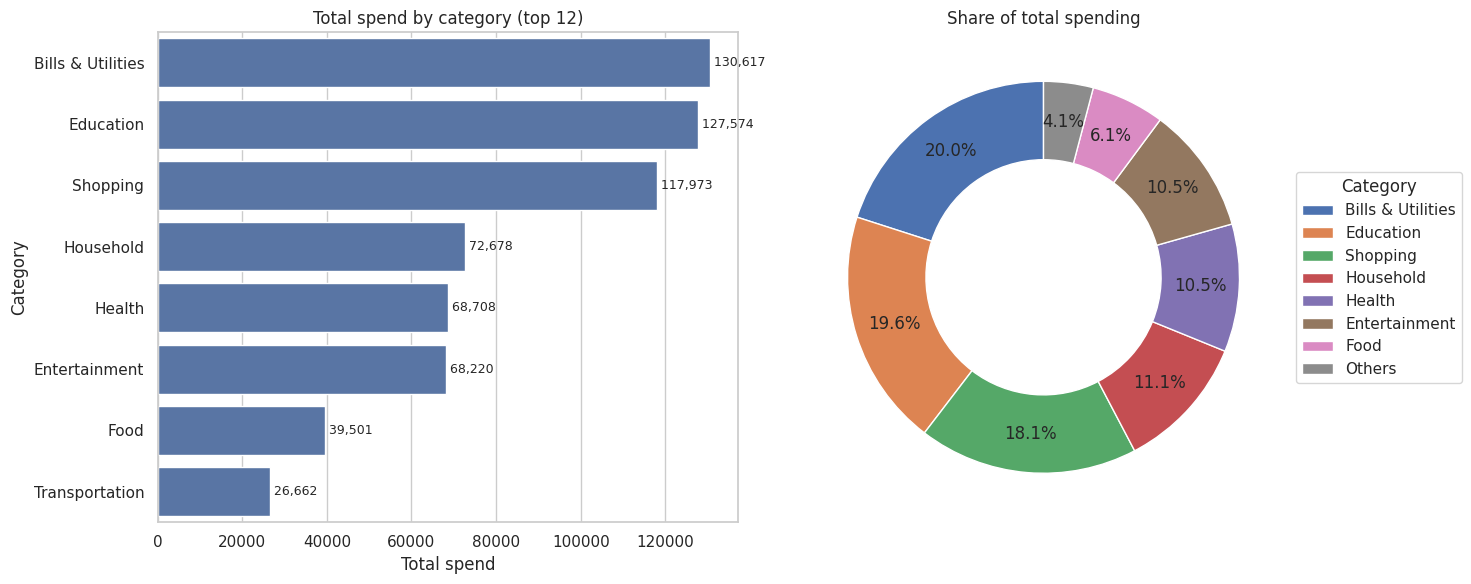

> **Insight:** Bills & Utilities dominates spending at 20.0% of the total; the bottom 1 categories together are only 4.1%.

In [ ]:
# Cell 20: EDA 1: category spending
# EDA 1: category-wise spending (bar chart + donut)
cat_spend = exp.groupby("category")["amount"].sum().sort_values(ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
top_n = cat_spend.head(12)
sns.barplot(x=top_n.values, y=top_n.index, ax=axes[0], color=sns.color_palette("deep")[0])
axes[0].set_title("Total spend by category (top 12)")
axes[0].set_xlabel("Total spend")
axes[0].set_ylabel("Category")
for i, v in enumerate(top_n.values):
    axes[0].text(v, i, f" {money(v)}", va="center", fontsize=9)

donut = pd.concat([cat_spend.head(7), pd.Series({"Others": cat_spend.iloc[7:].sum()})]) if len(cat_spend) > 7 else cat_spend
wedges, _, _ = axes[1].pie(donut.values, autopct="%1.1f%%", startangle=90, pctdistance=0.8,
                           wedgeprops=dict(width=0.4, edgecolor="white"))
axes[1].legend(wedges, donut.index, title="Category", loc="center left", bbox_to_anchor=(1, 0.5))
axes[1].set_title("Share of total spending")
save_fig("01_category_spending")
insight(f"{cat_spend.index[0]} dominates spending at {cat_spend.iloc[0] / cat_spend.sum() * 100:.1f}% of the total; "
        f"the bottom {max(len(cat_spend) - 7, 0)} categories together are only "
        f"{cat_spend.iloc[7:].sum() / cat_spend.sum() * 100:.1f}%.")

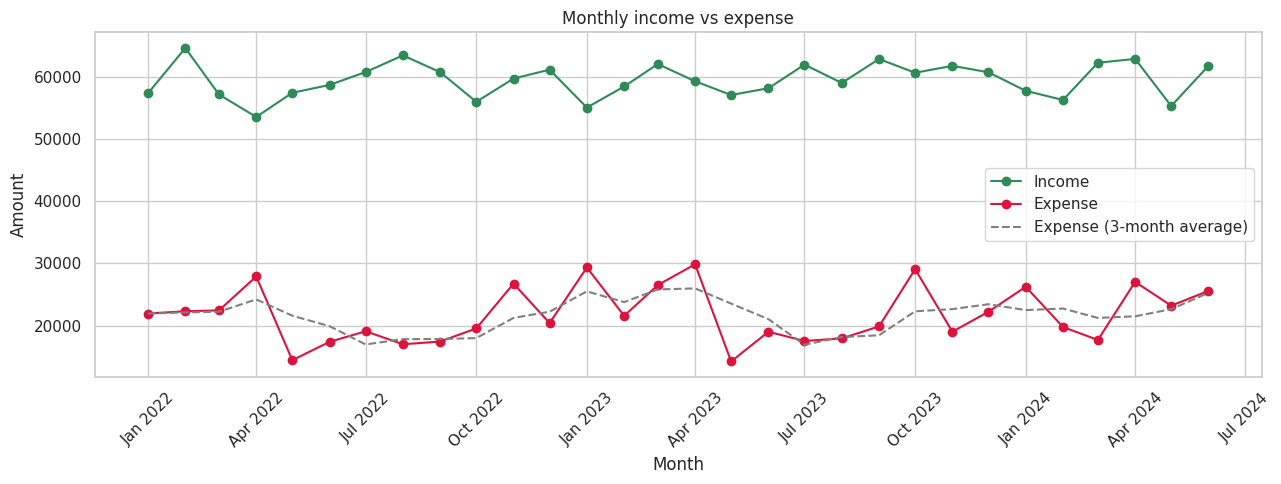

> **Insight:** Average monthly income is 59,515 against expense of 21,731 (average gap 37,784). Expense volatility (std) is 4,494.

In [ ]:
# Cell 21: EDA 2: monthly income vs expense
# EDA 2: monthly income vs expense trend (line chart)
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(monthly["month_start"], monthly["income"], marker="o", label="Income", color="seagreen")
ax.plot(monthly["month_start"], monthly["expense"], marker="o", label="Expense", color="crimson")
ax.plot(monthly["month_start"], monthly["expense_roll3"], linestyle="--", label="Expense (3-month average)", color="grey")
ax.set_title("Monthly income vs expense")
ax.set_xlabel("Month")
ax.set_ylabel("Amount")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.xticks(rotation=45)
ax.legend()
save_fig("02_monthly_income_vs_expense")
gap = (monthly["income"] - monthly["expense"]).mean()
insight(f"Average monthly income is {money(monthly['income'].mean())} against expense of {money(monthly['expense'].mean())} "
        f"(average gap {money(gap)}). Expense volatility (std) is {money(monthly['expense'].std())}.")

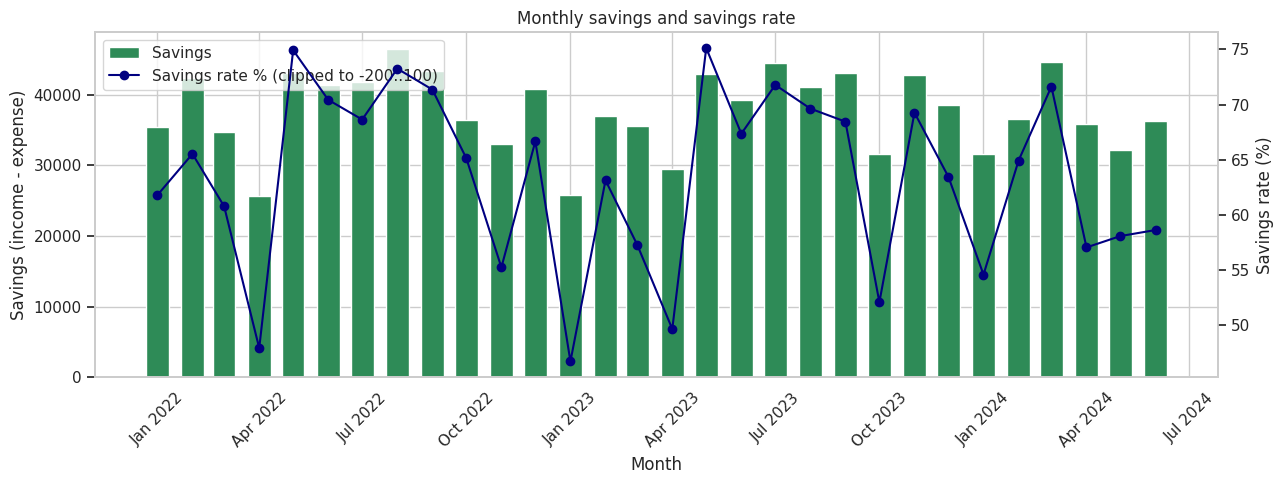

> **Insight:** Median savings rate is 65.0% over 30 months that recorded income; best month 2022-08, worst month 2022-04. Months with no recorded income show negative savings and no rate.

In [ ]:
# Cell 22: EDA 3: savings and savings rate
# EDA 3: monthly savings (bars) and savings rate (line)
fig, ax1 = plt.subplots(figsize=(13, 5))
colors = np.where(monthly["savings"] >= 0, "seagreen", "indianred")
ax1.bar(monthly["month_start"], monthly["savings"], width=20, color=colors, label="Savings")
ax1.set_xlabel("Month")
ax1.set_ylabel("Savings (income - expense)")
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.setp(ax1.get_xticklabels(), rotation=45)
ax2 = ax1.twinx()
ax2.plot(monthly["month_start"], monthly["savings_rate"].clip(-200, 100), color="navy", marker="o", label="Savings rate % (clipped to -200..100)")
ax2.set_ylabel("Savings rate (%)")
ax2.grid(False)
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper left")
ax1.set_title("Monthly savings and savings rate")
save_fig("03_savings_and_rate")
valid = monthly["savings_rate"].dropna()
insight(f"Median savings rate is {valid.median():.1f}% over {len(valid)} months that recorded income; "
        f"best month {monthly.loc[monthly['savings'].idxmax(), 'year_month']}, worst month {monthly.loc[monthly['savings'].idxmin(), 'year_month']}. "
        "Months with no recorded income show negative savings and no rate.")

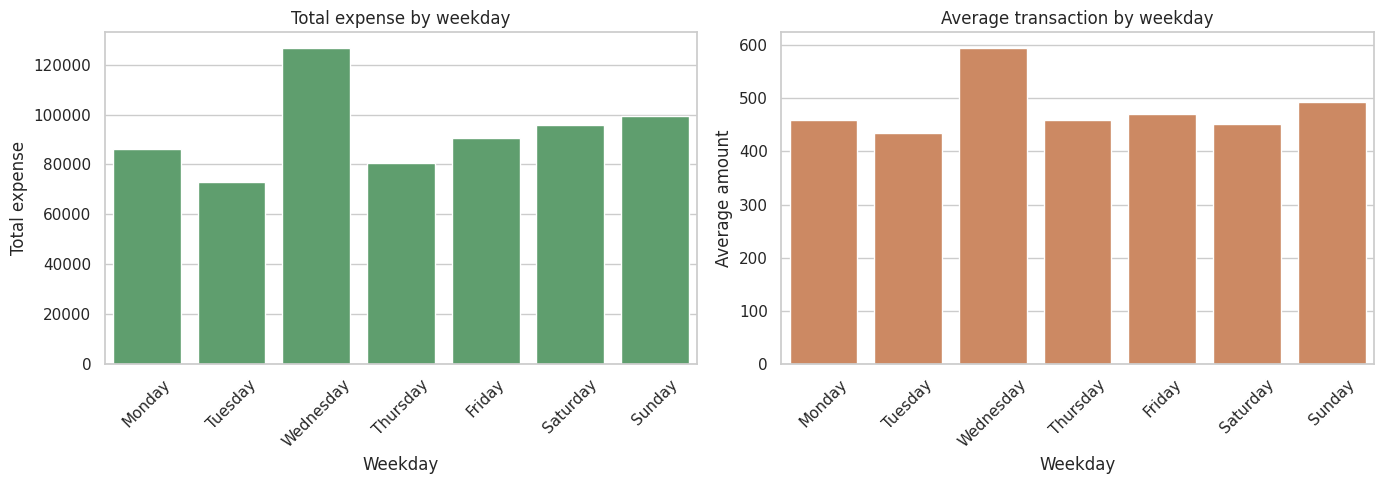

> **Insight:** Highest total spending falls on Wednesday; the largest average ticket is on Wednesday.

In [ ]:
# Cell 23: EDA 4: weekday spending
# EDA 4: spending by weekday
wd = exp.groupby("weekday")["amount"].agg(total="sum", average="mean", n="count").reindex(WEEKDAY_ORDER)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(x=wd.index, y=wd["total"], ax=axes[0], color=sns.color_palette("deep")[2])
axes[0].set_title("Total expense by weekday")
axes[0].set_xlabel("Weekday")
axes[0].set_ylabel("Total expense")
axes[0].tick_params(axis="x", rotation=45)
sns.barplot(x=wd.index, y=wd["average"], ax=axes[1], color=sns.color_palette("deep")[1])
axes[1].set_title("Average transaction by weekday")
axes[1].set_xlabel("Weekday")
axes[1].set_ylabel("Average amount")
axes[1].tick_params(axis="x", rotation=45)
save_fig("04_weekday_spending")
insight(f"Highest total spending falls on {wd['total'].idxmax()}; the largest average ticket is on {wd['average'].idxmax()}.")

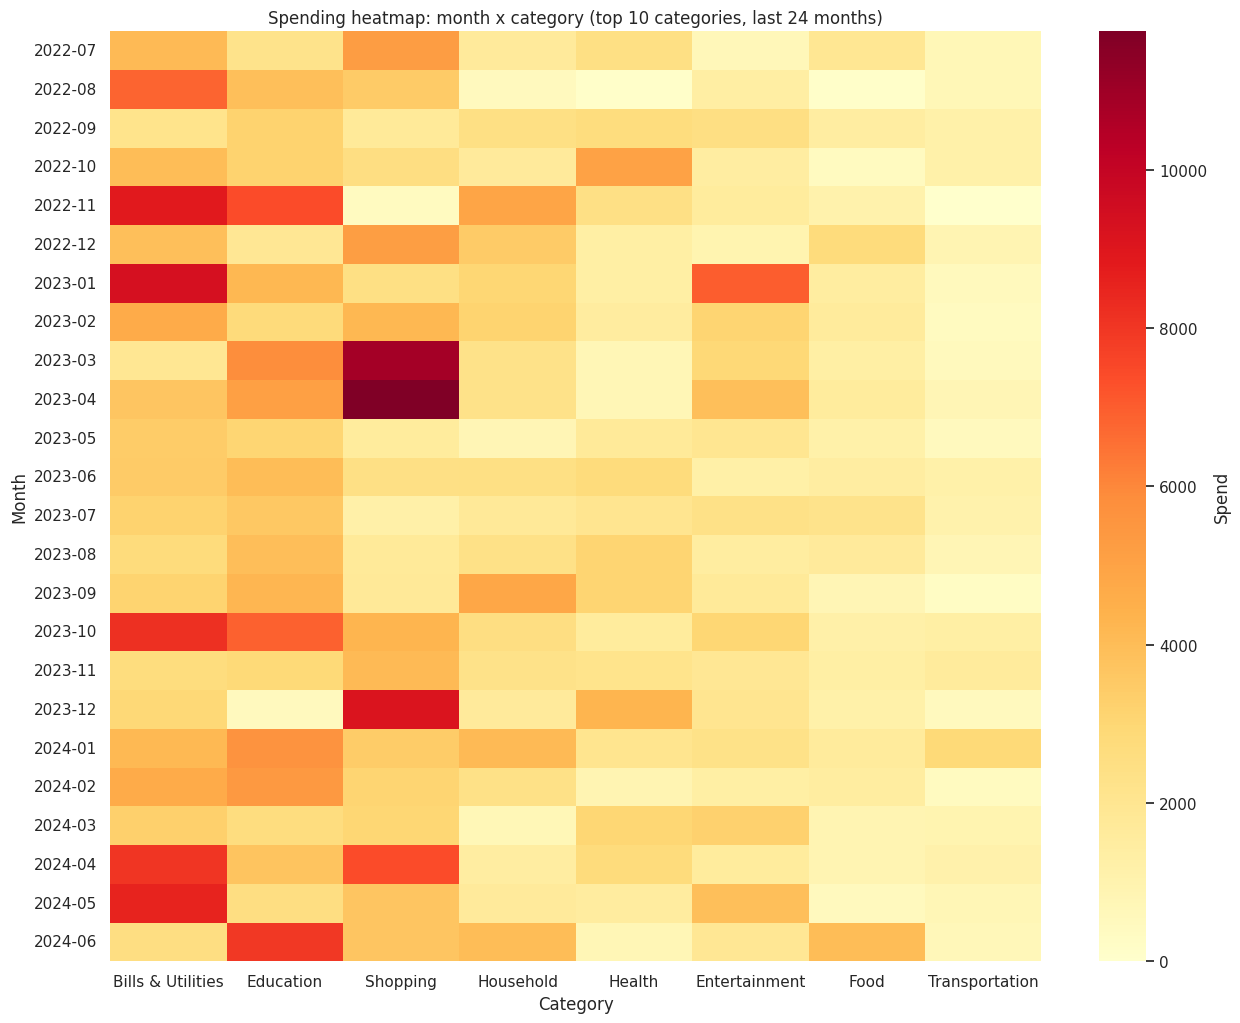

> **Insight:** The single hottest cell is Shopping in 2023-04 (11,750). Dark horizontal bands are heavy months; dark vertical bands are categories that are always expensive.

In [ ]:
# Cell 24: EDA 5: month x category heatmap
# EDA 5: spending heatmap (month x category)
top_cats = cat_spend.head(10).index
heat = (exp[exp["category"].isin(top_cats)].pivot_table(index="year_month", columns="category", values="amount",
                                                        aggfunc="sum", fill_value=0)[list(top_cats)].tail(24))
fig, ax = plt.subplots(figsize=(13, max(5, 0.35 * len(heat) + 2)))
sns.heatmap(heat, cmap="YlOrRd", ax=ax, annot=len(heat) <= 14, fmt=".0f", cbar_kws={"label": "Spend"})
ax.set_title("Spending heatmap: month x category (top 10 categories, last 24 months)")
ax.set_xlabel("Category")
ax.set_ylabel("Month")
save_fig("05_heatmap_month_category")
r, c = np.unravel_index(np.argmax(heat.values), heat.shape)
insight(f"The single hottest cell is {heat.columns[c]} in {heat.index[r]} ({money(heat.values[r, c])}). "
        "Dark horizontal bands are heavy months; dark vertical bands are categories that are always expensive.")

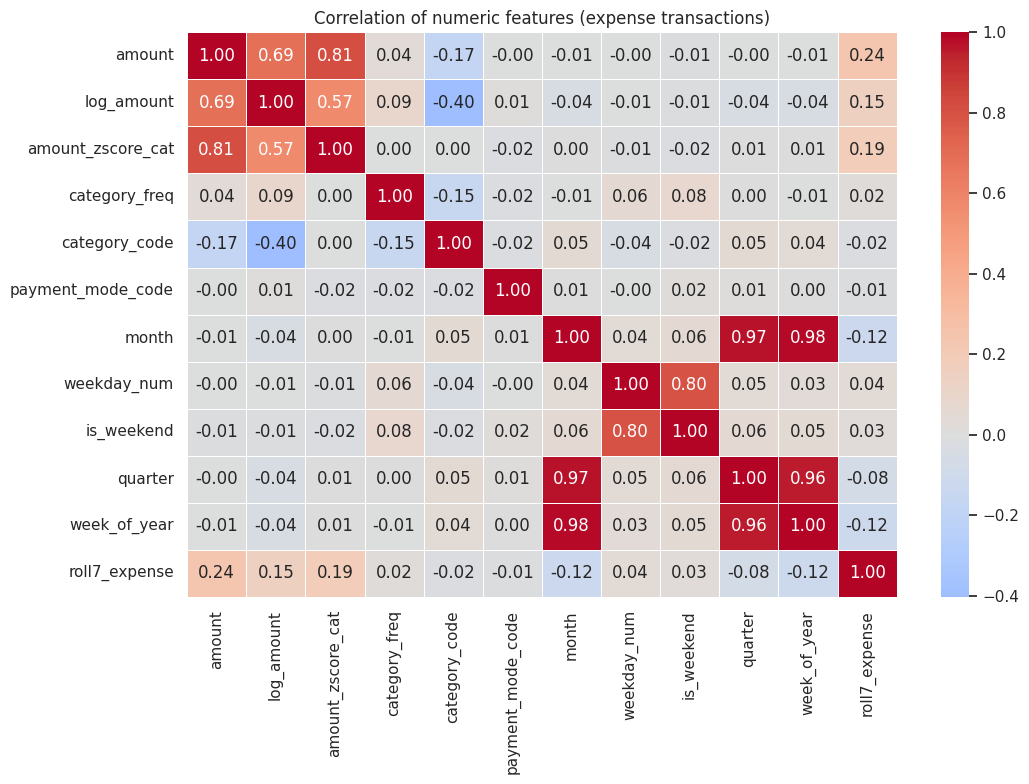

> **Insight:** Strongest relationship (excluding amount vs log amount): month and week_of_year (|r| = 0.98). Calendar features correlate weakly with amount, so spending size is driven mostly by category, not by the day.

In [ ]:
# Cell 25: EDA 6: correlation heatmap
# EDA 6: correlation heatmap of numeric features
num_cols = ["amount", "log_amount", "amount_zscore_cat", "category_freq", "category_code", "payment_mode_code",
            "month", "weekday_num", "is_weekend", "quarter", "week_of_year", "roll7_expense"]
corr = exp[num_cols].corr()
fig, ax = plt.subplots(figsize=(11, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax, linewidths=0.5)
ax.set_title("Correlation of numeric features (expense transactions)")
save_fig("06_correlation_heatmap")
pairs = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack().drop(
    labels=[("amount", "log_amount")], errors="ignore").abs().sort_values(ascending=False)
insight(f"Strongest relationship (excluding amount vs log amount): {pairs.index[0][0]} and {pairs.index[0][1]} (|r| = {pairs.iloc[0]:.2f}). "
        "Calendar features correlate weakly with amount, so spending size is driven mostly by category, not by the day.")

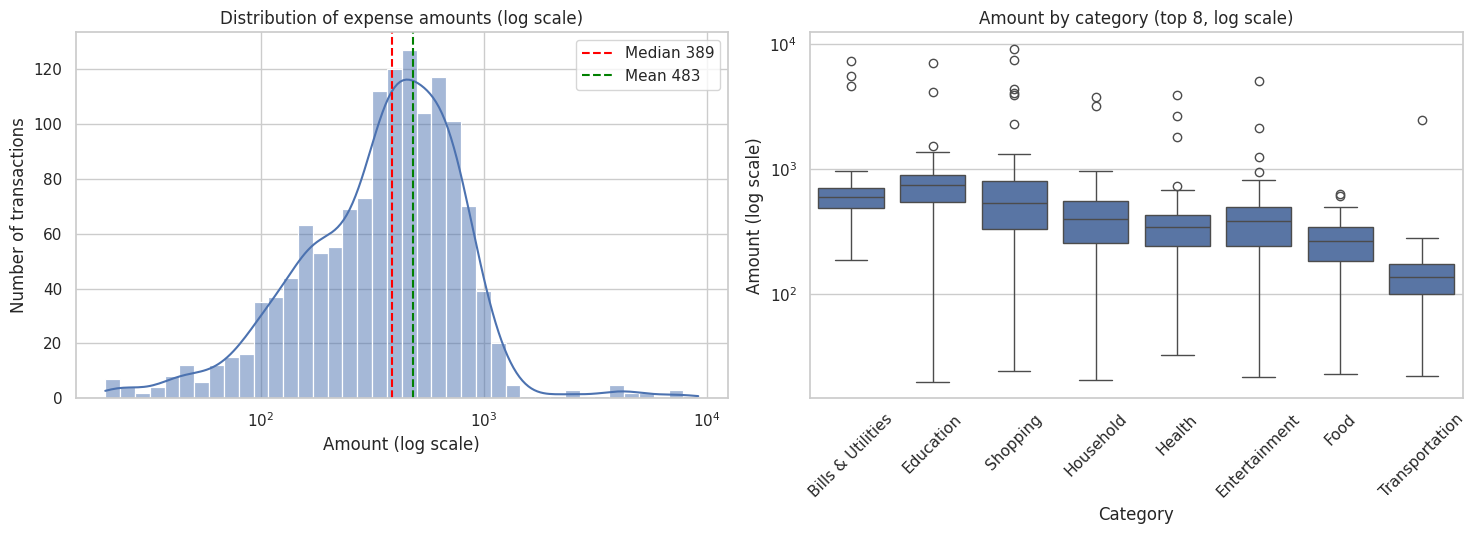

> **Insight:** Amounts are strongly right-skewed (skewness 7.9): most payments are small and a few are very large. 1.4% of expense rows are extreme outliers within their category.

In [ ]:
# Cell 26: EDA 7: amount distribution and boxplots
# EDA 7: distribution of transaction amounts (histogram + KDE, box plot by category)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
sns.histplot(exp["amount"], log_scale=True, kde=True, bins=40, ax=axes[0], color=sns.color_palette("deep")[0])
axes[0].axvline(exp["amount"].median(), color="red", linestyle="--", label=f"Median {money(exp['amount'].median())}")
axes[0].axvline(exp["amount"].mean(), color="green", linestyle="--", label=f"Mean {money(exp['amount'].mean())}")
axes[0].set_title("Distribution of expense amounts (log scale)")
axes[0].set_xlabel("Amount (log scale)")
axes[0].set_ylabel("Number of transactions")
axes[0].legend()
top8 = cat_spend.head(8).index
sns.boxplot(data=exp[exp["category"].isin(top8)], x="category", y="amount", order=list(top8), ax=axes[1])
axes[1].set_yscale("log")
axes[1].set_title("Amount by category (top 8, log scale)")
axes[1].set_xlabel("Category")
axes[1].set_ylabel("Amount (log scale)")
axes[1].tick_params(axis="x", rotation=45)
save_fig("07_amount_distribution")
skew = exp["amount"].skew()
insight(f"Amounts are strongly right-skewed (skewness {skew:.1f}): most payments are small and a few are very large. "
        f"{(exp['is_extreme_outlier'].mean() * 100):.1f}% of expense rows are extreme outliers within their category.")

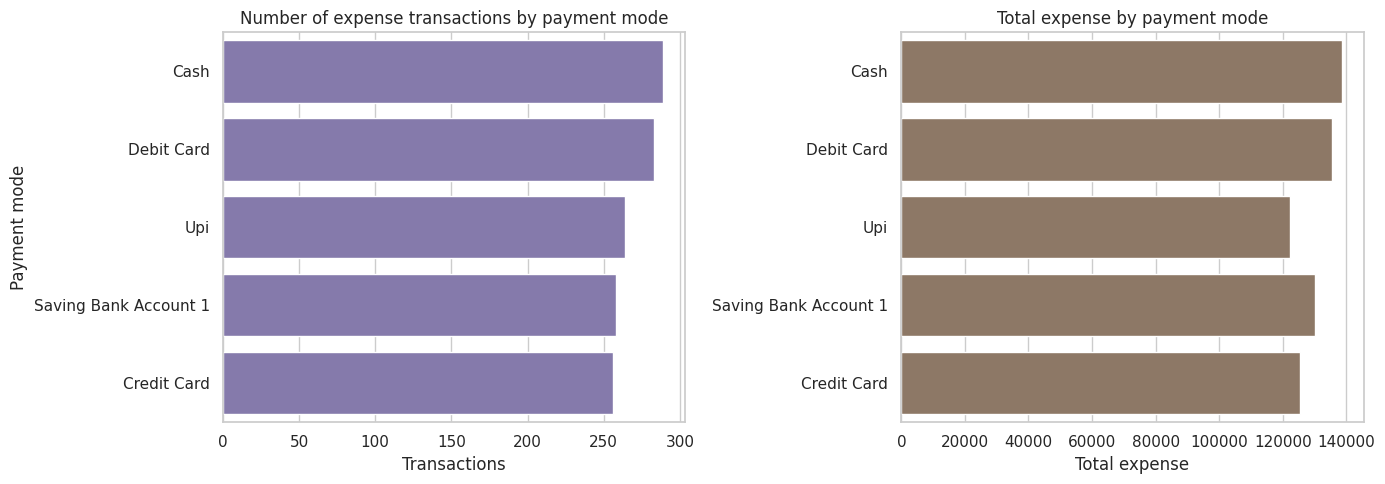

> **Insight:** Cash is used most often (289 transactions); Cash carries the largest total value (21.2% of spending).

In [ ]:
# Cell 27: EDA 8: payment mode
# EDA 8: payment mode distribution
pm = exp.groupby("payment_mode")["amount"].agg(n="count", total="sum").sort_values("n", ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(x=pm["n"], y=pm.index, ax=axes[0], color=sns.color_palette("deep")[4])
axes[0].set_title("Number of expense transactions by payment mode")
axes[0].set_xlabel("Transactions")
axes[0].set_ylabel("Payment mode")
sns.barplot(x=pm["total"], y=pm.index, ax=axes[1], color=sns.color_palette("deep")[5])
axes[1].set_title("Total expense by payment mode")
axes[1].set_xlabel("Total expense")
axes[1].set_ylabel("")
save_fig("08_payment_mode")
insight(f"{pm.index[0]} is used most often ({pm['n'].iloc[0]} transactions); {pm['total'].idxmax()} carries the largest total value "
        f"({pm['total'].max() / pm['total'].sum() * 100:.1f}% of spending).")

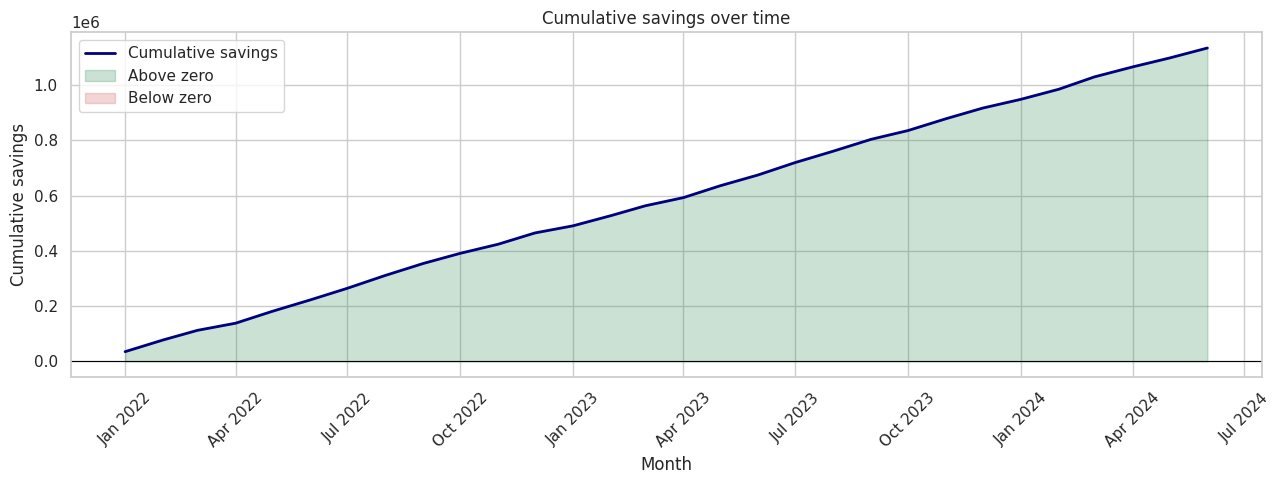

> **Insight:** Cumulative savings ended at 1,133,528 after 30 months, with a low point of 35,473 in 2022-01.

In [ ]:
# Cell 28: EDA 9: cumulative savings
# EDA 9: cumulative savings over time
fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(monthly["month_start"], monthly["cum_savings"], color="navy", linewidth=2, label="Cumulative savings")
ax.fill_between(monthly["month_start"], monthly["cum_savings"], 0, where=monthly["cum_savings"] >= 0, color="seagreen", alpha=0.25, label="Above zero")
ax.fill_between(monthly["month_start"], monthly["cum_savings"], 0, where=monthly["cum_savings"] < 0, color="indianred", alpha=0.25, label="Below zero")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Cumulative savings over time")
ax.set_xlabel("Month")
ax.set_ylabel("Cumulative savings")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.xticks(rotation=45)
ax.legend()
save_fig("09_cumulative_savings")
insight(f"Cumulative savings ended at {money(monthly['cum_savings'].iloc[-1])} after {len(monthly)} months, "
        f"with a low point of {money(monthly['cum_savings'].min())} in {monthly.loc[monthly['cum_savings'].idxmin(), 'year_month']}.")

## Section 6: Budget utilization

- **Budget per category** = 80th percentile of that category's historical monthly spend (months with spend). It is stored in the SQL `budget` table in Section 4 and can be overridden through `USER_BUDGET_OVERRIDES`.
- **Utilization %** = actual spend ÷ budget × 100, per category and month.
- **Status:** Safe (< 80%), Warning (80–100%), Exceeded (> 100%).

Because the budget is the 80th percentile, roughly 20% of active months are expected to exceed it by construction. That is a reasonable "stretch but realistic" budget, and a user can tighten it in the dashboard.

Budget utilization for the latest month in the data: 2024-06


,actual,budget,utilization_%,status
category,,,,
Food,4023.6,1622.0,248.1,Exceeded
Education,7950.9,5419.0,146.7,Exceeded
Household,4036.5,3066.0,131.7,Exceeded
Shopping,3692.9,5205.0,70.9,Safe
Entertainment,1923.5,3033.0,63.4,Safe
Transportation,655.0,1162.0,56.4,Safe
Bills & Utilities,2540.9,5270.0,48.2,Safe
Health,750.1,3092.0,24.3,Safe


Status counts: {'Safe': 5, 'Exceeded': 3}


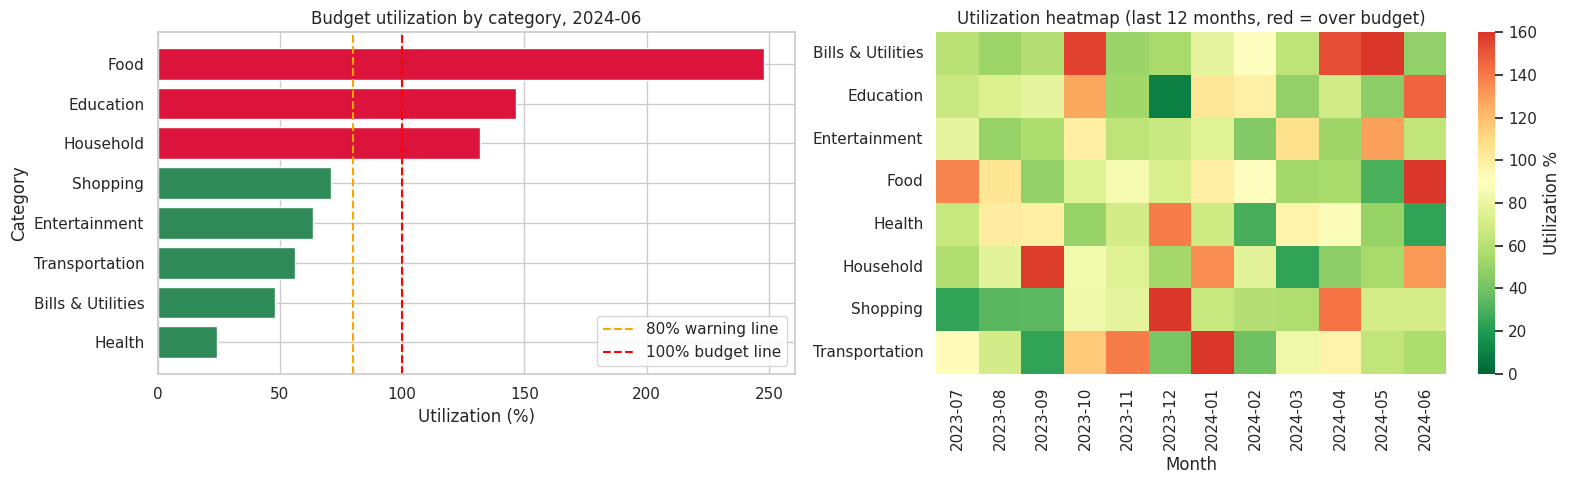

> **Insight:** In 2024-06, 3 categories exceeded budget and 0 were in the warning zone. Over the full history, Bills & Utilities goes over budget most often (20% of months).

In [ ]:
# Cell 30: budget utilization table and charts
# Budget utilization table, status, bar chart, heatmap
budget = get_data("SELECT category, monthly_budget, source FROM budget")
budget_s = budget.set_index("category")["monthly_budget"]
all_months = monthly["year_month"].tolist()

actual = (exp.pivot_table(index="year_month", columns="category", values="amount", aggfunc="sum", fill_value=0)
             .reindex(all_months, fill_value=0))
cols = [c for c in actual.columns if c in budget_s.index]
util = actual[cols].div(budget_s[cols], axis=1) * 100


def utilization_status(u: float) -> str:
    """Safe < 80%, Warning 80-100%, Exceeded > 100%."""
    return "Safe" if u < 80 else ("Warning" if u <= 100 else "Exceeded")


STATUS_COLORS = {"Safe": "seagreen", "Warning": "orange", "Exceeded": "crimson"}
latest = all_months[-1]
latest_tbl = pd.DataFrame({"actual": actual.loc[latest, cols], "budget": budget_s[cols],
                           "utilization_%": util.loc[latest]}).round(1)
latest_tbl["status"] = latest_tbl["utilization_%"].apply(utilization_status)
latest_tbl = latest_tbl.sort_values("utilization_%", ascending=False)
print(f"Budget utilization for the latest month in the data: {latest}")
display(latest_tbl)
print("Status counts:", latest_tbl["status"].value_counts().to_dict())

fig, axes = plt.subplots(1, 2, figsize=(16, max(5, 0.35 * len(cols) + 2)))
top_u = latest_tbl.head(15)
axes[0].barh(top_u.index[::-1], top_u["utilization_%"][::-1], color=[STATUS_COLORS[s] for s in top_u["status"][::-1]])
axes[0].axvline(80, color="orange", linestyle="--", label="80% warning line")
axes[0].axvline(100, color="red", linestyle="--", label="100% budget line")
axes[0].set_title(f"Budget utilization by category, {latest}")
axes[0].set_xlabel("Utilization (%)")
axes[0].set_ylabel("Category")
axes[0].legend()
recent_util = util.tail(12)
sns.heatmap(recent_util.T, cmap="RdYlGn_r", center=90, vmin=0, vmax=160, ax=axes[1],
            cbar_kws={"label": "Utilization %"}, annot=len(recent_util) <= 8, fmt=".0f")
axes[1].set_title("Utilization heatmap (last 12 months, red = over budget)")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("")
save_fig("10_budget_utilization")

exceeded_share = (util > 100).mean().sort_values(ascending=False) * 100
insight(f"In {latest}, {int((latest_tbl['status'] == 'Exceeded').sum())} categories exceeded budget and "
        f"{int((latest_tbl['status'] == 'Warning').sum())} were in the warning zone. Over the full history, "
        f"{exceeded_share.index[0]} goes over budget most often ({exceeded_share.iloc[0]:.0f}% of months).")

In [ ]:
# Cell 31: gauge-style budget view
# Gauge-style view of budget utilization (overall + the 3 categories closest to their limits)
overall_util = actual.loc[latest, cols].sum() / budget_s[cols].sum() * 100
gauge_items = [("Overall budget", overall_util)] + [(c, latest_tbl.loc[c, "utilization_%"]) for c in latest_tbl.index[:3]]
fig = go.Figure()
for i, (name, val) in enumerate(gauge_items):
    top = max(150, float(val) * 1.1)
    fig.add_trace(go.Indicator(
        mode="gauge+number", value=float(val), number={"suffix": "%", "valueformat": ".0f"},
        title={"text": name}, domain={"row": 0, "column": i},
        gauge={"axis": {"range": [0, top]}, "bar": {"color": "#1f2937"},
               "steps": [{"range": [0, 80], "color": "#86efac"}, {"range": [80, 100], "color": "#fde68a"},
                         {"range": [100, top], "color": "#fca5a5"}]}))
fig.update_layout(grid={"rows": 1, "columns": len(gauge_items), "pattern": "independent"},
                  title=f"Budget gauges, {latest} (green < 80%, amber 80-100%, red > 100%)", height=320)
fig.show()

## Section 7: Anomaly detection (Isolation Forest)

**Idea:** Isolation Forest isolates observations with random splits. Points that are separated from the rest after only a few splits (short path length) are unusual.

**Features:** `amount`, `log_amount`, `category_code`, `weekday_num`, `month`, `is_weekend`, `amount_zscore_cat`, `category_freq`, all standardized with `StandardScaler`.

**Contamination:** the expected share of anomalies. We look at how many expenses are statistical outliers by two independent rules (|z| > 3 and the 3×IQR fence) and choose a value in the 2–5% range. A lower value gives fewer, more confident alerts, which is preferable for a personal-finance tool where too many alerts get ignored.

**Validation (the point of this section):** an unsupervised model has no labels, so we check its output against a simple independent definition of "unusual": a flagged transaction is *genuinely unusual* if it is more than 2 standard deviations above its category mean **or** above the 95th percentile of its category.

In [ ]:
# Cell 33: train Isolation Forest
# Prepare features, scale, train Isolation Forest, add anomaly_flag and anomaly_score
from sklearn.ensemble import IsolationForest

ANOMALY_FEATURES = ["amount", "log_amount", "category_code", "weekday_num", "month", "is_weekend",
                    "amount_zscore_cat", "category_freq"]
exp = df[df["type"] == "Expense"].copy()

# Evidence for choosing the contamination level
share_z3 = (exp["amount_zscore_cat"].abs() > 3).mean() * 100
share_iqr = exp["is_extreme_outlier"].mean() * 100
print(f"Expense rows with |z| > 3 inside their category: {share_z3:.2f}%")
print(f"Expense rows beyond the 3 x IQR fence:            {share_iqr:.2f}%")
CONTAMINATION = 0.03
print(f"Chosen contamination: {CONTAMINATION:.0%} (inside the 2-5% range; the two rules above are the sanity check)")

scaler = StandardScaler()
X_scaled = scaler.fit_transform(exp[ANOMALY_FEATURES])
iso = IsolationForest(n_estimators=300, contamination=CONTAMINATION, random_state=RANDOM_STATE, n_jobs=-1)
iso.fit(X_scaled)

exp["anomaly_flag"] = (iso.predict(X_scaled) == -1).astype(int)       # 1 = anomaly
exp["anomaly_score"] = -iso.score_samples(X_scaled)                   # higher = more unusual
print(f"\nFlagged {int(exp['anomaly_flag'].sum())} of {len(exp)} expense transactions "
      f"({exp['anomaly_flag'].mean() * 100:.2f}%)")

Expense rows with |z| > 3 inside their category: 1.41%
Expense rows beyond the 3 x IQR fence:            1.41%
Chosen contamination: 3% (inside the 2-5% range; the two rules above are the sanity check)

Flagged 41 of 1350 expense transactions (3.04%)


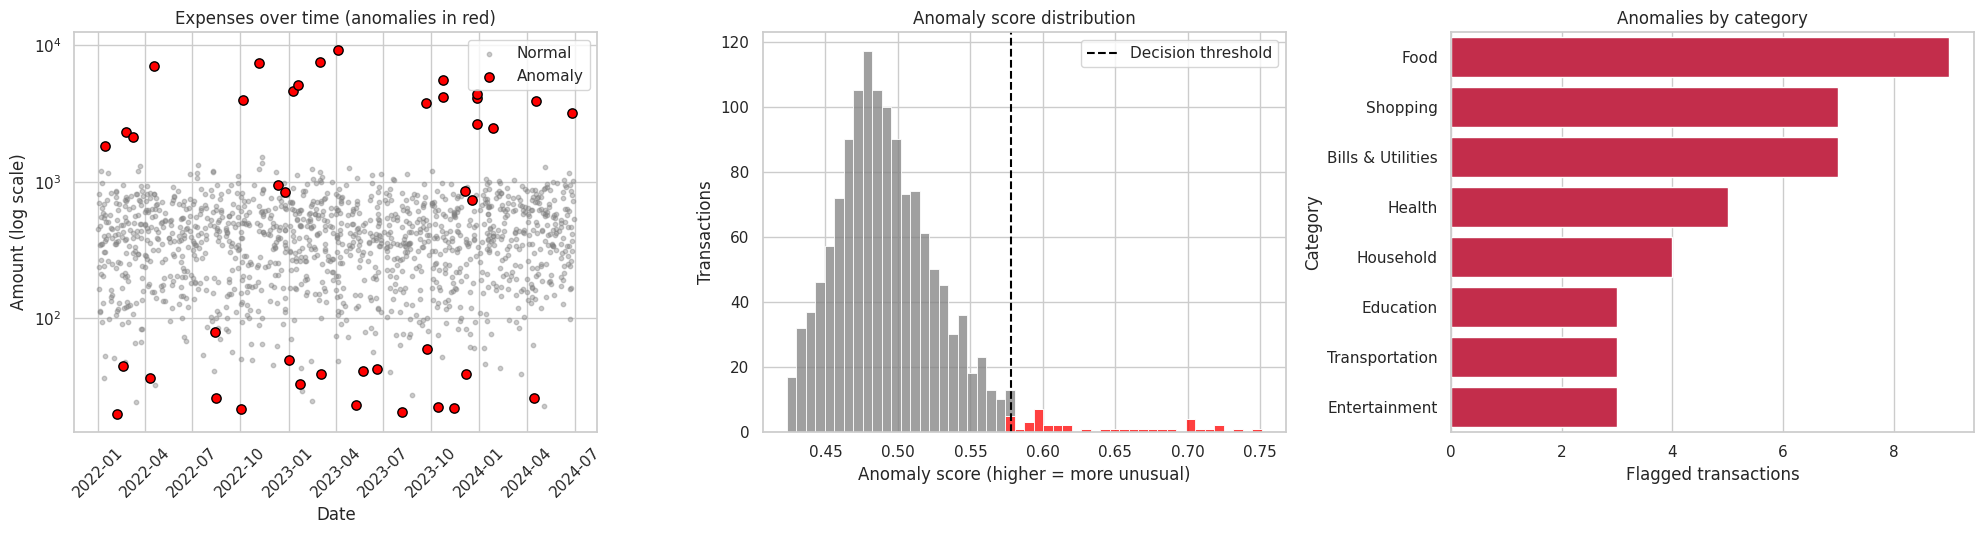

Top 20 flagged transactions (highest anomaly score):


,txn_id,date,category,subcategory,payment_mode,amount,anomaly_score,note
465,466,2022-11-05 16:15:00,Bills & Utilities,Bills & Utilities Sub,Credit Card,7370.27,0.751,
994,995,2023-10-22 14:54:00,Bills & Utilities,Bills & Utilities Sub,Debit Card,5548.54,0.734,
702,703,2023-04-05 09:19:00,Shopping,Shopping Sub,Saving Bank Account 1,9153.19,0.724,
182,183,2022-04-17 16:23:00,Education,Education Sub,Cash,7022.04,0.724,
575,576,2023-01-18 20:35:00,Entertainment,Entertainment Sub,Cash,5114.83,0.712,
560,561,2023-01-09 15:00:00,Bills & Utilities,Bills & Utilities Sub,Debit Card,4639.61,0.707,
646,647,2023-03-02 19:32:00,Shopping,Shopping Sub,Upi,7520.55,0.705,
996,997,2023-10-22 17:30:00,Education,Education Sub,Credit Card,4165.08,0.701,
425,426,2022-10-06 15:57:00,Health,Health Sub,Debit Card,3950.41,0.700,
1141,1142,2024-01-26 11:42:00,Transportation,Transportation Sub,Debit Card,2496.83,0.699,


In [ ]:
# Cell 34: anomaly plots and top 20 table
# Anomaly visualizations: scatter (date vs amount), score distribution, category-wise counts
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
normal, flagged = exp[exp["anomaly_flag"] == 0], exp[exp["anomaly_flag"] == 1]
axes[0].scatter(normal["date"], normal["amount"], s=10, alpha=0.4, color="grey", label="Normal")
axes[0].scatter(flagged["date"], flagged["amount"], s=45, color="red", edgecolor="black", label="Anomaly")
axes[0].set_yscale("log")
axes[0].set_title("Expenses over time (anomalies in red)")
axes[0].set_xlabel("Date")
axes[0].set_ylabel("Amount (log scale)")
axes[0].tick_params(axis="x", rotation=45)
axes[0].legend()

sns.histplot(data=exp, x="anomaly_score", hue="anomaly_flag", bins=50, palette={0: "grey", 1: "red"}, ax=axes[1], multiple="stack")
axes[1].axvline(-iso.offset_, color="black", linestyle="--", label="Decision threshold")
axes[1].set_title("Anomaly score distribution")
axes[1].set_xlabel("Anomaly score (higher = more unusual)")
axes[1].set_ylabel("Transactions")
axes[1].legend()

cnt = flagged["category"].value_counts()
sns.barplot(x=cnt.values, y=cnt.index, ax=axes[2], color="crimson")
axes[2].set_title("Anomalies by category")
axes[2].set_xlabel("Flagged transactions")
axes[2].set_ylabel("Category")
save_fig("11_anomaly_overview")

print("Top 20 flagged transactions (highest anomaly score):")
top20 = (flagged.sort_values("anomaly_score", ascending=False)
         [["txn_id", "date", "category", "subcategory", "payment_mode", "amount", "anomaly_score", "note"]].head(20).round(3))
display(top20)

Flagged transactions compared with their category (top 20):


,date,category,amount,cat_mean,cat_median,cat_std,std_devs_above_mean,times_median,genuinely_unusual
465,2022-11-05 16:15:00,Bills & Utilities,7370.27,687.46,598.80,687.76,9.72,12.31,True
994,2023-10-22 14:54:00,Bills & Utilities,5548.54,687.46,598.80,687.76,7.07,9.27,True
702,2023-04-05 09:19:00,Shopping,9153.19,728.23,536.84,1038.48,8.11,17.05,True
182,2022-04-17 16:23:00,Education,7022.04,773.18,742.62,626.65,9.97,9.46,True
575,2023-01-18 20:35:00,Entertainment,5114.83,429.05,387.92,447.07,10.48,13.19,True
560,2023-01-09 15:00:00,Bills & Utilities,4639.61,687.46,598.80,687.76,5.75,7.75,True
646,2023-03-02 19:32:00,Shopping,7520.55,728.23,536.84,1038.48,6.54,14.01,True
996,2023-10-22 17:30:00,Education,4165.08,773.18,742.62,626.65,5.41,5.61,True
425,2022-10-06 15:57:00,Health,3950.41,375.45,346.22,361.52,9.89,11.41,True
1141,2024-01-26 11:42:00,Transportation,2496.83,151.49,136.62,185.87,12.62,18.28,True



How many flagged / unflagged transactions are genuinely unusual (%):


,n,share_z_gt_2,share_above_p95,share_genuinely_unusual
Not flagged,1309,0.2,4.0,4.0
Flagged,41,43.9,48.8,48.8


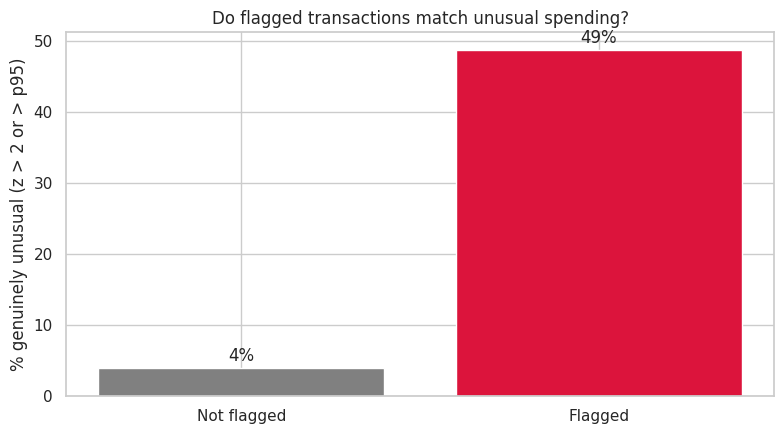

### Validation conclusion
- **49%** of flagged transactions are genuinely unusual for their category, against **4%** of unflagged ones (12.3x higher). Overall the Isolation Forest output **does NOT clearly match unusual spending behaviour**.
- Median size of a flagged transaction is **1.4x** the median of its category, and **0.3** standard deviations above its category mean.
- 21 flagged transaction(s) did not pass the simple amount test. These are not necessarily false alarms: the model also looks at category rarity, weekday and month, so it can flag an ordinary amount in a rare situation. They are listed below for manual review.

,date,category,subcategory,amount,cat_median,z_vs_category,anomaly_score,note
341,2022-08-14 13:27:00,Food,Food Sub,26.16,267.28,-1.97,0.65,
651,2023-03-04 19:59:00,Food,Food Sub,39.14,267.28,-1.86,0.62,
1061,2023-12-06 12:07:00,Food,Food Sub,38.88,267.28,-1.87,0.61,
65,2022-02-07 17:48:00,Education,Education Sub,20.08,742.62,-1.20,0.61,
581,2023-01-22 11:18:00,Health,Health Sub,32.93,346.22,-0.95,0.61,
750,2023-05-10 15:33:00,Food,Food Sub,23.19,267.28,-2.00,0.60,
876,2023-08-06 17:10:00,Household,Household Sub,20.56,403.68,-1.06,0.60,
802,2023-06-19 15:16:00,Food,Food Sub,42.48,267.28,-1.84,0.60,
951,2023-09-23 08:44:00,Food,Food Sub,60.23,267.28,-1.69,0.60,
409,2022-10-01 11:36:00,Household,Household Sub,21.58,403.68,-1.06,0.60,


In [ ]:
# Cell 35: validate anomalies against category statistics
# VALIDATION: compare flagged transactions with category statistics
stats = exp.groupby("category")["amount"].agg(cat_mean="mean", cat_median="median", cat_std="std",
                                              cat_p95=lambda s: s.quantile(0.95))
exp = exp.drop(columns=[c for c in stats.columns if c in exp.columns]).join(stats, on="category")
exp["z_vs_category"] = ((exp["amount"] - exp["cat_mean"]) / exp["cat_std"].replace(0, np.nan)).fillna(0.0)
exp["x_median"] = exp["amount"] / exp["cat_median"]
exp["above_z2"] = exp["z_vs_category"] > 2
exp["above_p95"] = exp["amount"] > exp["cat_p95"]
exp["genuinely_unusual"] = exp["above_z2"] | exp["above_p95"]

flagged = exp[exp["anomaly_flag"] == 1].sort_values("anomaly_score", ascending=False)
print("Flagged transactions compared with their category (top 20):")
display(flagged[["date", "category", "amount", "cat_mean", "cat_median", "cat_std", "z_vs_category", "x_median", "genuinely_unusual"]]
        .head(20).round(2).rename(columns={"z_vs_category": "std_devs_above_mean", "x_median": "times_median"}))

# Share of flagged vs unflagged transactions that are genuinely unusual (baseline comparison)
cmp = exp.groupby("anomaly_flag").agg(n=("amount", "size"),
                                      share_z_gt_2=("above_z2", "mean"),
                                      share_above_p95=("above_p95", "mean"),
                                      share_genuinely_unusual=("genuinely_unusual", "mean")) * [1, 100, 100, 100]
cmp.index = ["Not flagged", "Flagged"]
cmp["n"] = cmp["n"].astype(int)
print("\nHow many flagged / unflagged transactions are genuinely unusual (%):")
display(cmp.round(1))

flag_share = float(cmp.loc["Flagged", "share_genuinely_unusual"])
base_share = float(cmp.loc["Not flagged", "share_genuinely_unusual"])
lift = flag_share / base_share if base_share > 0 else np.inf
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(["Not flagged", "Flagged"], [base_share, flag_share], color=["grey", "crimson"])
ax.set_ylabel("% genuinely unusual (z > 2 or > p95)")
ax.set_title("Do flagged transactions match unusual spending?")
for i, v in enumerate([base_share, flag_share]):
    ax.text(i, v + 1, f"{v:.0f}%", ha="center")
save_fig("12_anomaly_validation")

not_confirmed = flagged[~flagged["genuinely_unusual"]]
verdict = ("MATCHES unusual spending behaviour" if flag_share >= 70 and lift >= 2
           else "PARTLY matches unusual spending behaviour" if flag_share >= 50
           else "does NOT clearly match unusual spending behaviour")
display(Markdown(
    f"### Validation conclusion\n"
    f"- **{flag_share:.0f}%** of flagged transactions are genuinely unusual for their category, against **{base_share:.0f}%** of unflagged ones "
    f"({lift:.1f}x higher). Overall the Isolation Forest output **{verdict}**.\n"
    f"- Median size of a flagged transaction is **{flagged['x_median'].median():.1f}x** the median of its category, "
    f"and **{flagged['z_vs_category'].median():.1f}** standard deviations above its category mean.\n"
    f"- {len(not_confirmed)} flagged transaction(s) did not pass the simple amount test. These are not necessarily false alarms: the model also "
    f"looks at category rarity, weekday and month, so it can flag an ordinary amount in a rare situation. They are listed below for manual review."))
if len(not_confirmed):
    display(not_confirmed[["date", "category", "subcategory", "amount", "cat_median", "z_vs_category", "anomaly_score", "note"]].round(2))

### How to read the validation

- The p95 rule is true for about 5% of *any* group by definition, so the unflagged column is a baseline. A good detector should be far above it.
- Because `amount_zscore_cat` is one of the model's inputs, a strong match with the z-score rule is partly expected. The more informative check is the **lift** (flagged vs unflagged) and the manual review of flagged items that did not pass the amount test.
- Isolation Forest is unsupervised. The honest claim is "flagged items are consistent with unusual spending", not "every flag is fraud or a mistake".

In [ ]:
# Cell 37: save anomalies to SQL
# Save anomalies to SQL table "anomalies" and persist the model objects for the dashboard
import joblib


def explain_anomaly(row) -> str:
    """Plain-English explanation of why a transaction was flagged."""
    text = (f"{row['category']} payment of {row['amount']:,.0f} is {row['x_median']:.1f}x the usual (median) {row['category']} "
            f"payment of {row['cat_median']:,.0f} and {row['z_vs_category']:.1f} standard deviations above the category average of {row['cat_mean']:,.0f}.")
    if not row["genuinely_unusual"]:
        text += " The amount alone is not extreme; the combination of category, timing and size is rare."
    return text


anom = exp[exp["anomaly_flag"] == 1].copy()
anom["explanation"] = anom.apply(explain_anomaly, axis=1)
anom_sql = pd.DataFrame({
    "txn_id": anom["txn_id"], "date": anom["date"].dt.strftime("%Y-%m-%d %H:%M:%S"), "category": anom["category"],
    "amount": anom["amount"], "anomaly_score": anom["anomaly_score"], "anomaly_flag": 1,
    "category_mean": anom["cat_mean"], "category_std": anom["cat_std"], "z_score": anom["z_vs_category"],
    "explanation": anom["explanation"]})
try:
    conn = get_connection()
    conn.execute("DELETE FROM anomalies")
    anom_sql.to_sql("anomalies", conn, if_exists="append", index=False)
    conn.commit()
    conn.close()
    print(f"Saved {len(anom_sql)} anomalies to table 'anomalies'.")
except Exception as e:
    raise RuntimeError(f"Could not write anomalies: {e}")

# Bundle used by the dashboard to score newly added transactions
try:
    anomaly_bundle = {"scaler": scaler, "model": iso, "features": ANOMALY_FEATURES, "contamination": CONTAMINATION,
                      "category_map": dict(zip(df["category"], df["category_code"]))}
    joblib.dump(anomaly_bundle, os.path.join(OUT_DIR, "anomaly_model.pkl"))
    print("Saved anomaly_model.pkl")
except Exception as e:
    print("Could not save anomaly model:", e)

display(get_data("""SELECT a.txn_id, substr(a.date, 1, 10) AS date, a.category, ROUND(a.amount, 2) AS amount,
                           ROUND(a.z_score, 2) AS z_score, ROUND(a.anomaly_score, 3) AS score, t.payment_mode
                    FROM anomalies a JOIN transactions t ON t.txn_id = a.txn_id
                    ORDER BY a.anomaly_score DESC LIMIT 10"""))
print("SQL check: the query above reads the anomalies back with a JOIN to the transactions table.")

Saved 41 anomalies to table 'anomalies'.
Saved anomaly_model.pkl


,txn_id,date,category,amount,z_score,score,payment_mode
0,466,2022-11-05,Bills & Utilities,7370.27,9.72,0.751,Credit Card
1,995,2023-10-22,Bills & Utilities,5548.54,7.07,0.734,Debit Card
2,703,2023-04-05,Shopping,9153.19,8.11,0.724,Saving Bank Account 1
3,183,2022-04-17,Education,7022.04,9.97,0.724,Cash
4,576,2023-01-18,Entertainment,5114.83,10.48,0.712,Cash
5,561,2023-01-09,Bills & Utilities,4639.61,5.75,0.707,Debit Card
6,647,2023-03-02,Shopping,7520.55,6.54,0.705,Upi
7,997,2023-10-22,Education,4165.08,5.41,0.701,Credit Card
8,426,2022-10-06,Health,3950.41,9.89,0.700,Debit Card
9,1142,2024-01-26,Transportation,2496.83,12.62,0.699,Debit Card


SQL check: the query above reads the anomalies back with a JOIN to the transactions table.


## Section 8: Expense prediction (regression)

**Target:** next month's total expense. **Features (all known at the start of the month):** last month's expense (`lag1`), the expense two months ago (`lag2`), the mean of the previous 3 months (`roll3_prev`), month-of-year as a sine/cosine pair (seasonality), and a time index `t` (trend).

**Method**
1. Time-aware split: first 80% of months = train, last 20% = **held-out test** (no shuffling).
2. Compare Linear Regression, Ridge, Random Forest and Gradient Boosting, each inside a scikit-learn `Pipeline` (scaler → model), plus a naive "same as last month" baseline for reference.
3. `TimeSeriesSplit` cross-validation **on the training months only** picks the best model; `GridSearchCV` (also time-aware) tunes it.
4. Held-out metrics: MAE, RMSE, R², MAPE.
5. The chosen model is refit on all months and used to forecast the next 3 months.

Model selection uses cross-validation, not the test set, so the held-out score stays an honest estimate.

In [ ]:
# Cell 39: monthly supervised dataset and time split
# Build the supervised monthly dataset (lag + rolling + seasonal + trend features)
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV, cross_val_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.base import clone

FEATURES = ["lag1", "lag2", "roll3_prev", "month_sin", "month_cos", "t"]


def make_supervised(expense: pd.Series, month_nums: pd.Series) -> pd.DataFrame:
    """Turn a monthly expense series into a feature table. Every feature uses only earlier months."""
    d = pd.DataFrame({"expense": expense.values, "month_num": month_nums.values})
    d["lag1"] = d["expense"].shift(1)
    d["lag2"] = d["expense"].shift(2)
    d["roll3_prev"] = d["expense"].shift(1).rolling(3).mean()
    d["month_sin"] = np.sin(2 * np.pi * d["month_num"] / 12)
    d["month_cos"] = np.cos(2 * np.pi * d["month_num"] / 12)
    d["t"] = np.arange(len(d))
    return d


sup = make_supervised(monthly["expense"], monthly["month_num"])
sup.insert(0, "year_month", monthly["year_month"].values)
sup = sup.dropna().reset_index(drop=True)
print("Supervised monthly dataset:", sup.shape)
display(sup.head())

n = len(sup)
if n < 12:
    print(f"WARNING: only {n} usable months. Metrics will be very noisy; treat results as a demonstration.")
n_test = max(3, int(round(n * 0.2)))
n_train = n - n_test
X_train, y_train = sup.loc[:n_train - 1, FEATURES], sup.loc[:n_train - 1, "expense"]
X_test, y_test = sup.loc[n_train:, FEATURES], sup.loc[n_train:, "expense"]
print(f"Train months: {n_train} ({sup['year_month'].iloc[0]} to {sup['year_month'].iloc[n_train - 1]})")
print(f"Held-out test months: {n_test} ({sup['year_month'].iloc[n_train]} to {sup['year_month'].iloc[-1]})")

Supervised monthly dataset: (27, 9)


,year_month,expense,month_num,lag1,lag2,roll3_prev,month_sin,month_cos,t
0,2022-04,27893.09,4,22430.17,22293.94,22217.103333,8.660254e-01,-0.500000,3
1,2022-05,14410.05,5,27893.09,22430.17,24205.733333,5.000000e-01,-0.866025,4
2,2022-06,17370.06,6,14410.05,27893.09,21577.770000,1.224647e-16,-1.000000,5
3,2022-07,19067.49,7,17370.06,14410.05,19891.066667,-5.000000e-01,-0.866025,6
4,2022-08,16981.22,8,19067.49,17370.06,16949.200000,-8.660254e-01,-0.500000,7


Train months: 22 (2022-04 to 2024-01)
Held-out test months: 5 (2024-02 to 2024-06)


In [ ]:
# Cell 40: train, compare, cross-validate and tune models
# Train and compare 4 models + naive baseline with TimeSeriesSplit CV, then tune the best by CV
def regression_metrics(y_true, y_pred) -> dict:
    """MAE, RMSE, R2 and MAPE (MAPE ignores months with zero actual spend)."""
    y_true, y_pred = np.asarray(y_true, dtype=float), np.asarray(y_pred, dtype=float)
    nz = y_true != 0
    mape = float(np.mean(np.abs((y_true[nz] - y_pred[nz]) / y_true[nz])) * 100) if nz.any() else np.nan
    return {"MAE": float(mean_absolute_error(y_true, y_pred)),
            "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
            "R2": float(r2_score(y_true, y_pred)), "MAPE_%": mape}


def make_pipe(estimator) -> Pipeline:
    """Scaler + model pipeline (scaling matters for Ridge/Linear, harmless for trees)."""
    return Pipeline([("scaler", StandardScaler()), ("model", estimator)])


BASE_MODELS = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(alpha=1.0, random_state=RANDOM_STATE),
    "Random Forest": RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingRegressor(random_state=RANDOM_STATE),
}
PARAM_GRIDS = {
    "Linear Regression": {},
    "Ridge": {"model__alpha": [0.01, 0.1, 1, 10, 100]},
    "Random Forest": {"model__n_estimators": [200, 400], "model__max_depth": [2, 3, 5, None], "model__min_samples_leaf": [1, 2, 4]},
    "Gradient Boosting": {"model__n_estimators": [100, 200], "model__learning_rate": [0.03, 0.1],
                          "model__max_depth": [2, 3], "model__subsample": [0.8, 1.0]},
}

k_splits = int(max(2, min(5, n_train // 6)))
tscv = TimeSeriesSplit(n_splits=k_splits)
print(f"TimeSeriesSplit with {k_splits} folds on {n_train} training months")

rows, fitted, preds = [], {}, {}
naive_pred = X_test["lag1"].values
rows.append({"Model": "Naive (same as last month)", "CV_RMSE": np.nan, **regression_metrics(y_test, naive_pred)})
preds["Naive (same as last month)"] = naive_pred

cv_rmse = {}
for name, est in BASE_MODELS.items():
    pipe = make_pipe(clone(est))
    scores = cross_val_score(pipe, X_train, y_train, cv=tscv, scoring="neg_root_mean_squared_error")
    cv_rmse[name] = float(-scores.mean())
    pipe.fit(X_train, y_train)
    fitted[name] = pipe
    preds[name] = pipe.predict(X_test)
    rows.append({"Model": name, "CV_RMSE": cv_rmse[name], **regression_metrics(y_test, preds[name])})

best_name = min(cv_rmse, key=cv_rmse.get)           # chosen by cross-validation on TRAIN data only
print("CV RMSE (train only):", {k: round(v, 1) for k, v in cv_rmse.items()})
print("Best model by cross-validation:", best_name)

if PARAM_GRIDS[best_name]:
    gs = GridSearchCV(make_pipe(clone(BASE_MODELS[best_name])), PARAM_GRIDS[best_name], cv=tscv,
                      scoring="neg_root_mean_squared_error", n_jobs=-1)
    gs.fit(X_train, y_train)
    tuned, best_params, tuned_cv = gs.best_estimator_, gs.best_params_, float(-gs.best_score_)
else:
    tuned, best_params, tuned_cv = fitted[best_name], {}, cv_rmse[best_name]
tuned_label = f"{best_name} (tuned)"
tuned_pred = tuned.predict(X_test)
preds[tuned_label] = tuned_pred
fitted[tuned_label] = tuned
rows.append({"Model": tuned_label, "CV_RMSE": tuned_cv, **regression_metrics(y_test, tuned_pred)})
print("Best parameters:", best_params)

results = pd.DataFrame(rows).sort_values("RMSE").reset_index(drop=True)
print("\nHeld-out test results (sorted by RMSE; lower is better):")
display(results.round(2))

best_by_test = results[results["Model"] != "Naive (same as last month)"].iloc[0]["Model"]
if best_by_test != tuned_label:
    print(f"Note: '{best_by_test}' scored best on the small test set, but '{tuned_label}' was chosen by cross-validation "
          "(selecting on the test set would leak information). With only a few test months, small differences are noise.")

TimeSeriesSplit with 3 folds on 22 training months
CV RMSE (train only): {'Linear Regression': 11383.8, 'Ridge': 6453.9, 'Random Forest': 5416.0, 'Gradient Boosting': 7221.5}
Best model by cross-validation: Random Forest
Best parameters: {'model__max_depth': 2, 'model__min_samples_leaf': 2, 'model__n_estimators': 400}

Held-out test results (sorted by RMSE; lower is better):


,Model,CV_RMSE,MAE,RMSE,R2,MAPE_%
0,Naive (same as last month),NaN,4824.08,5551.25,-1.52,21.00
1,Random Forest (tuned),4998.78,5618.29,5833.65,-1.78,26.44
2,Random Forest,5416.01,5865.74,6166.76,-2.11,27.86
3,Ridge,6453.91,6683.80,7766.68,-3.94,32.43
4,Gradient Boosting,7221.47,8086.89,8268.82,-4.59,37.81
5,Linear Regression,11383.79,9409.40,10252.58,-7.60,45.07


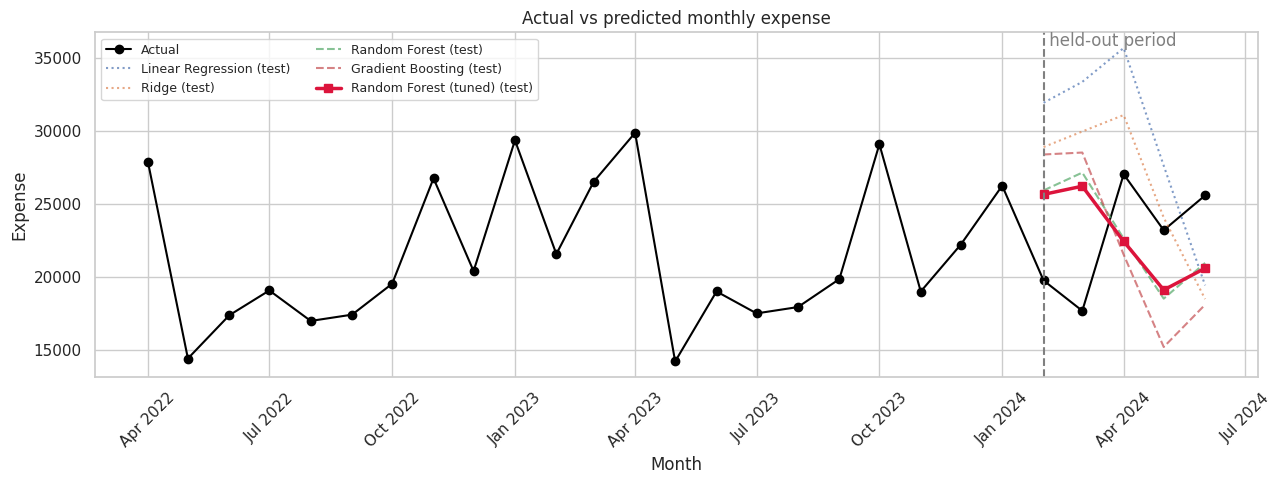

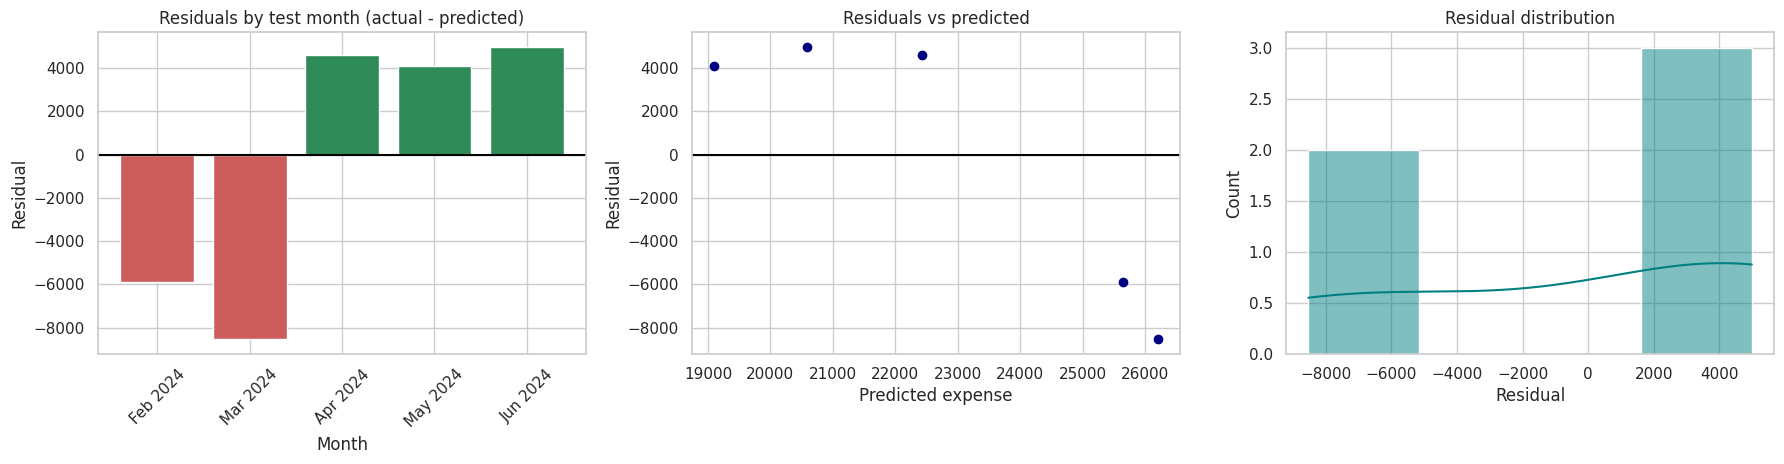

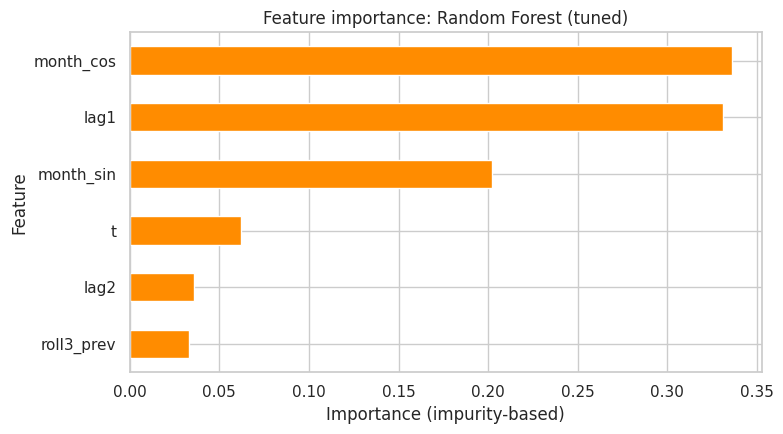

> **Insight:** Most influential feature: **month_cos**. Mean residual on the test months is -150 (positive = the model under-predicts on average).

In [ ]:
# Cell 41: actual vs predicted, residuals, feature importance
# Actual vs predicted, residuals, feature importance
test_months = pd.to_datetime(sup.loc[n_train:, "year_month"] + "-01")
all_months_dt = pd.to_datetime(sup["year_month"] + "-01")

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(all_months_dt, sup["expense"], color="black", marker="o", label="Actual")
styles = {"Linear Regression": ":", "Ridge": ":", "Random Forest": "--", "Gradient Boosting": "--"}
for name, style in styles.items():
    ax.plot(test_months, preds[name], style, alpha=0.7, label=f"{name} (test)")
ax.plot(test_months, preds[tuned_label], color="crimson", marker="s", linewidth=2.5, label=f"{tuned_label} (test)")
ax.axvline(test_months.iloc[0], color="grey", linestyle="--")
ax.text(test_months.iloc[0], ax.get_ylim()[1], " held-out period", va="top", color="grey")
ax.set_title("Actual vs predicted monthly expense")
ax.set_xlabel("Month")
ax.set_ylabel("Expense")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.xticks(rotation=45)
ax.legend(ncol=2, fontsize=9)
save_fig("13_actual_vs_predicted")

resid = y_test.values - tuned_pred
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
axes[0].bar(test_months.dt.strftime("%b %Y"), resid, color=np.where(resid >= 0, "seagreen", "indianred"))
axes[0].axhline(0, color="black")
axes[0].set_title("Residuals by test month (actual - predicted)")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Residual")
axes[0].tick_params(axis="x", rotation=45)
axes[1].scatter(tuned_pred, resid, color="navy")
axes[1].axhline(0, color="black")
axes[1].set_title("Residuals vs predicted")
axes[1].set_xlabel("Predicted expense")
axes[1].set_ylabel("Residual")
sns.histplot(resid, kde=len(resid) > 3, ax=axes[2], color="teal")
axes[2].set_title("Residual distribution")
axes[2].set_xlabel("Residual")
save_fig("14_residuals")

final_est = tuned.named_steps["model"]
if hasattr(final_est, "feature_importances_"):
    importance, imp_label = final_est.feature_importances_, "Importance (impurity-based)"
elif hasattr(final_est, "coef_"):
    importance = np.abs(final_est.coef_) / np.abs(final_est.coef_).sum()
    imp_label = "Relative |coefficient| (features standardized)"
else:
    importance, imp_label = np.zeros(len(FEATURES)), "Importance"
imp = pd.Series(importance, index=FEATURES).sort_values()
fig, ax = plt.subplots(figsize=(8, 4.5))
imp.plot(kind="barh", ax=ax, color="darkorange")
ax.set_title(f"Feature importance: {tuned_label}")
ax.set_xlabel(imp_label)
ax.set_ylabel("Feature")
save_fig("15_feature_importance")
insight(f"Most influential feature: **{imp.index[-1]}**. Mean residual on the test months is {money(resid.mean())} "
        f"(positive = the model under-predicts on average).")

Forecast for the next 3 months (range = prediction +/- 1.96 x held-out RMSE, a rough guide):


,year_month,predicted_expense,lower,upper
0,2024-07,21984.0,10550.0,33418.0
1,2024-08,23919.0,12485.0,35353.0
2,2024-09,24070.0,12636.0,35504.0


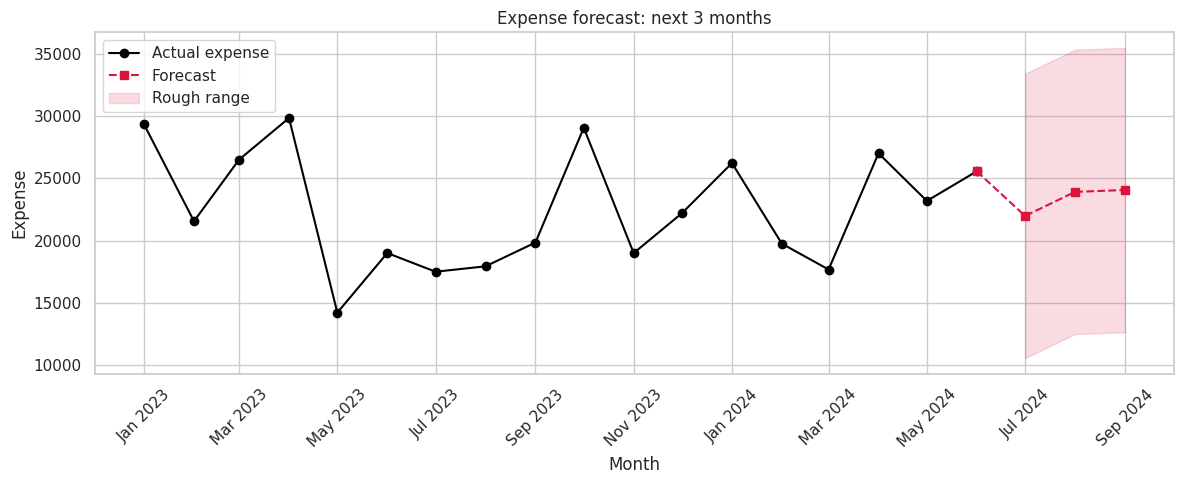

Saved model.pkl, metrics.json and forecast.csv in /content/outputs


In [ ]:
# Cell 42: final model, 3-month forecast, save model and metrics
# Final model (refit on ALL months), 3-month recursive forecast, save model + metrics
def recursive_forecast(model, expense_history: list, last_period: pd.Period, steps: int = 3) -> pd.DataFrame:
    """Predict `steps` future months one at a time, feeding each prediction back as the next month's lag."""
    hist = list(map(float, expense_history))
    t_next = len(hist)
    out = []
    for k in range(1, steps + 1):
        period = last_period + k
        feats = {"lag1": hist[-1], "lag2": hist[-2], "roll3_prev": float(np.mean(hist[-3:])),
                 "month_sin": np.sin(2 * np.pi * period.month / 12), "month_cos": np.cos(2 * np.pi * period.month / 12),
                 "t": t_next}
        pred = float(model.predict(pd.DataFrame([feats])[FEATURES])[0])
        pred = max(pred, 0.0)
        out.append({"year_month": str(period), "predicted_expense": pred})
        hist.append(pred)
        t_next += 1
    return pd.DataFrame(out)


final_model = clone(tuned).fit(sup[FEATURES], sup["expense"])      # same hyper-parameters, trained on all months
last_period = pd.Period(monthly["year_month"].iloc[-1], freq="M")
forecast = recursive_forecast(final_model, monthly["expense"].tolist(), last_period, steps=3)
heldout = regression_metrics(y_test, tuned_pred)
rmse = heldout["RMSE"]
forecast["lower"] = (forecast["predicted_expense"] - 1.96 * rmse).clip(lower=0)
forecast["upper"] = forecast["predicted_expense"] + 1.96 * rmse
print("Forecast for the next 3 months (range = prediction +/- 1.96 x held-out RMSE, a rough guide):")
display(forecast.round(0))

hist_tail = monthly.tail(18)
fc_dates = pd.to_datetime(forecast["year_month"] + "-01")
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(hist_tail["month_start"], hist_tail["expense"], marker="o", color="black", label="Actual expense")
ax.plot(pd.concat([hist_tail["month_start"].tail(1), fc_dates]),
        [hist_tail["expense"].iloc[-1]] + forecast["predicted_expense"].tolist(), marker="s", color="crimson", linestyle="--", label="Forecast")
ax.fill_between(fc_dates, forecast["lower"], forecast["upper"], color="crimson", alpha=0.15, label="Rough range")
ax.set_title("Expense forecast: next 3 months")
ax.set_xlabel("Month")
ax.set_ylabel("Expense")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
plt.xticks(rotation=45)
ax.legend()
save_fig("16_forecast")

try:
    joblib.dump({"model": final_model, "features": FEATURES, "model_name": tuned_label,
                 "heldout_rmse": rmse, "trained_on_months": len(sup)}, os.path.join(OUT_DIR, "model.pkl"))
    metrics = {"best_model": tuned_label, "best_params": {k: (v if not isinstance(v, np.generic) else v.item()) for k, v in best_params.items()},
               "selection_method": "TimeSeriesSplit cross-validation on training months", "n_train_months": int(n_train),
               "n_test_months": int(n_test), "heldout_metrics": heldout,
               "comparison_table": results.round(4).to_dict(orient="records"),
               "forecast": forecast.round(2).to_dict(orient="records"),
               "anomaly_detection": {"contamination": CONTAMINATION, "flagged": int(exp["anomaly_flag"].sum()),
                                     "flagged_genuinely_unusual_pct": round(flag_share, 1),
                                     "unflagged_genuinely_unusual_pct": round(base_share, 1)},
               "data_source": DATA_SOURCE}
    with open(os.path.join(OUT_DIR, "metrics.json"), "w") as f:
        json.dump(metrics, f, indent=2, default=str)
    forecast.to_csv(os.path.join(OUT_DIR, "forecast.csv"), index=False)
    print("Saved model.pkl, metrics.json and forecast.csv in", OUT_DIR)
except Exception as e:
    raise RuntimeError(f"Could not save model or metrics: {e}")

In [ ]:
# Cell 43: interpret regression results
# Plain-language reading of the regression results (generated from the numbers above)
mean_exp = float(y_test.mean())
naive_rmse = float(results.loc[results["Model"] == "Naive (same as last month)", "RMSE"].iloc[0])
beats_naive = rmse < naive_rmse
display(Markdown(
    f"### Interpretation\n"
    f"- **Chosen model:** {tuned_label}, picked by time-series cross-validation, tested on {n_test} unseen months.\n"
    f"- **Typical error:** MAE {money(heldout['MAE'])} per month, which is {heldout['MAE'] / mean_exp * 100:.0f}% of the average test-month expense "
    f"({money(mean_exp)}). RMSE is {money(rmse)}, MAPE {heldout['MAPE_%']:.1f}%, R² {heldout['R2']:.2f}.\n"
    f"- **Versus the naive baseline** (\"same as last month\", RMSE {money(naive_rmse)}): the model "
    f"{'**is better**, so it adds value beyond simply repeating last month' if beats_naive else '**is not better**, so for this data the simple baseline is just as useful and the forecast should be treated with caution'}.\n"
    f"- **Next month forecast:** about {money(forecast['predicted_expense'].iloc[0])} (rough range {money(forecast['lower'].iloc[0])} to {money(forecast['upper'].iloc[0])})."))

### Interpretation
- **Chosen model:** Random Forest (tuned), picked by time-series cross-validation, tested on 5 unseen months.
- **Typical error:** MAE 5,618 per month, which is 25% of the average test-month expense (22,642). RMSE is 5,834, MAPE 26.4%, R² -1.78.
- **Versus the naive baseline** ("same as last month", RMSE 5,551): the model **is not better**, so for this data the simple baseline is just as useful and the forecast should be treated with caution.
- **Next month forecast:** about 21,984 (rough range 10,550 to 33,418).

### Limitations of the expense model

- **Small sample.** A few dozen monthly points, and only a handful of test months, so metrics (especially R²) are noisy. A negative R² on the test set means the model did worse than predicting the test average.
- **History only.** The model sees past spending, not salary changes, festivals, trips, loans or one-off purchases, which usually drive big months.
- **Recursive forecasting.** Months 2 and 3 are built on earlier predictions, so their uncertainty grows. The shown range is a rough guide, not a statistical prediction interval.
- **Trees cannot extrapolate.** If spending trends beyond anything seen in training, Random Forest and Gradient Boosting flatten out. Linear models can follow a trend but miss non-linear effects.
- **Data quality.** The last month in the data may be incomplete, which would look like a drop in spending. Months with no transactions were treated as zero.
- **Improvements:** more history, category-level models, holiday and income features, and re-training each month.

## Section 9: Interactive visualizations (Plotly)

Hover over any point for details. Use the legend (click to hide, double-click to isolate), dropdown menus, range sliders and the animation slider as filters. Every figure is also saved as an HTML file in `outputs/charts/`.

In [ ]:
# Cell 46: Plotly: monthly trend
# Plotly 1: interactive monthly trend (range slider + selector buttons)
def save_html(fig, name: str) -> None:
    """Save an interactive Plotly figure as a standalone HTML file."""
    try:
        fig.write_html(os.path.join(CHART_DIR, f"{name}.html"), include_plotlyjs="cdn")
    except Exception as e:
        print("Could not save", name, e)


fig = go.Figure()
fig.add_trace(go.Scatter(x=monthly["month_start"], y=monthly["income"], name="Income", mode="lines+markers", line=dict(color="seagreen")))
fig.add_trace(go.Scatter(x=monthly["month_start"], y=monthly["expense"], name="Expense", mode="lines+markers", line=dict(color="crimson")))
fig.add_trace(go.Scatter(x=monthly["month_start"], y=monthly["expense_roll3"], name="Expense, 3-month average",
                         mode="lines", line=dict(color="grey", dash="dash")))
fig.update_layout(title="Monthly income vs expense (drag the slider below to zoom)", xaxis_title="Month", yaxis_title="Amount",
                  hovermode="x unified", template="plotly_white",
                  xaxis=dict(rangeslider=dict(visible=True),
                             rangeselector=dict(buttons=[dict(count=6, label="6m", step="month", stepmode="backward"),
                                                         dict(count=1, label="1y", step="year", stepmode="backward"),
                                                         dict(step="all", label="All")])))
fig.show()
save_html(fig, "p1_monthly_trend")

In [ ]:
# Cell 47: Plotly: category drill-down
# Plotly 2: category drill-down (sunburst + category dropdown for the monthly trend)
sun = exp.groupby(["category", "subcategory"], as_index=False)["amount"].sum()
top_for_sun = cat_spend.head(10).index
fig = px.sunburst(sun[sun["category"].isin(top_for_sun)], path=["category", "subcategory"], values="amount",
                  title="Category drill-down: click a category to zoom into its subcategories")
fig.update_layout(height=550)
fig.show()
save_html(fig, "p2_category_sunburst")

cats_dd = list(cat_spend.head(12).index)
cat_month = exp.pivot_table(index="year_month", columns="category", values="amount", aggfunc="sum", fill_value=0).reindex(all_months, fill_value=0)
fig = go.Figure()
for i, c in enumerate(cats_dd):
    fig.add_trace(go.Bar(x=cat_month.index, y=cat_month[c], name=c, visible=(i == 0)))
fig.update_layout(
    title="Monthly spend for the selected category (use the dropdown)", xaxis_title="Month", yaxis_title="Spend", template="plotly_white",
    updatemenus=[dict(type="dropdown", x=0.0, y=1.18, buttons=[
        dict(label=c, method="update", args=[{"visible": [j == i for j in range(len(cats_dd))]}, {"title": f"Monthly spend: {c}"}])
        for i, c in enumerate(cats_dd)])])
fig.show()
save_html(fig, "p2_category_dropdown")

In [ ]:
# Cell 48: Plotly: budget utilization
# Plotly 3: budget utilization (animated month slider) + category filter via legend
anim = util.tail(12).reset_index().melt(id_vars="year_month", var_name="category", value_name="utilization_pct")
anim["status"] = anim["utilization_pct"].apply(utilization_status)
anim["utilization_pct"] = anim["utilization_pct"].round(1)
fig = px.bar(anim, x="category", y="utilization_pct", color="status", animation_frame="year_month",
             color_discrete_map={"Safe": "#2e8b57", "Warning": "#f5a623", "Exceeded": "#dc143c"},
             category_orders={"status": ["Safe", "Warning", "Exceeded"]},
             range_y=[0, max(150, float(anim["utilization_pct"].max()) * 1.05)],
             title="Budget utilization by category (press play or drag the month slider)",
             labels={"utilization_pct": "Utilization (%)", "category": "Category", "year_month": "Month"})
fig.add_hline(y=100, line_dash="dash", line_color="red", annotation_text="100% of budget")
fig.add_hline(y=80, line_dash="dot", line_color="orange", annotation_text="80% warning")
fig.update_layout(template="plotly_white", height=520)
fig.show()
save_html(fig, "p3_budget_utilization")

In [ ]:
# Cell 49: Plotly: savings pattern
# Plotly 4: savings pattern (bars + savings rate line, dual axis)
from plotly.subplots import make_subplots

fig = make_subplots(specs=[[{"secondary_y": True}]])
fig.add_trace(go.Bar(x=monthly["month_start"], y=monthly["savings"], name="Savings",
                     marker_color=np.where(monthly["savings"] >= 0, "#2e8b57", "#cd5c5c")), secondary_y=False)
fig.add_trace(go.Scatter(x=monthly["month_start"], y=monthly["savings_rate"].clip(-200, 100), name="Savings rate (%)",
                         mode="lines+markers", line=dict(color="navy")), secondary_y=True)
fig.add_trace(go.Scatter(x=monthly["month_start"], y=monthly["cum_savings"], name="Cumulative savings",
                         mode="lines", line=dict(color="darkorange", dash="dot")), secondary_y=False)
fig.update_layout(title="Savings pattern: monthly savings, savings rate and cumulative savings", template="plotly_white",
                  hovermode="x unified", xaxis=dict(rangeslider=dict(visible=True)))
fig.update_yaxes(title_text="Savings", secondary_y=False)
fig.update_yaxes(title_text="Savings rate (%)", secondary_y=True)
fig.show()
save_html(fig, "p4_savings_pattern")

In [ ]:
# Cell 50: Plotly: anomaly scatter
# Plotly 5: anomaly scatter with hover details and category filter (legend)
plot_df = exp.copy()
plot_df["status"] = np.where(plot_df["anomaly_flag"] == 1, "Anomaly", "Normal")
fig = px.scatter(plot_df, x="date", y="amount", color="status", symbol="status", log_y=True,
                 color_discrete_map={"Normal": "#b0b0b0", "Anomaly": "#e60000"},
                 hover_data={"category": True, "subcategory": True, "payment_mode": True, "note": True,
                             "anomaly_score": ":.3f", "z_vs_category": ":.1f", "date": "|%d %b %Y", "status": False},
                 title="Anomaly explorer: hover for details, click legend items to filter", labels={"amount": "Amount (log scale)", "date": "Date"})
fig.update_traces(marker=dict(size=7, opacity=0.65), selector=dict(name="Normal"))
fig.update_traces(marker=dict(size=12, line=dict(width=1, color="black")), selector=dict(name="Anomaly"))
fig.update_layout(template="plotly_white", height=520)
fig.show()
save_html(fig, "p5_anomaly_scatter")

# Category filter version: dropdown selects which category's transactions are shown
cats_f = ["All"] + list(cat_spend.head(12).index)
fig = go.Figure()
for c in cats_f:
    sub = plot_df if c == "All" else plot_df[plot_df["category"] == c]
    fig.add_trace(go.Scatter(x=sub["date"], y=sub["amount"], mode="markers", name=c, visible=(c == "All"),
                             marker=dict(color=np.where(sub["anomaly_flag"] == 1, "red", "lightgrey"),
                                         size=np.where(sub["anomaly_flag"] == 1, 11, 6), line=dict(width=0.5, color="black")),
                             text=sub["category"] + " | " + sub["note"].astype(str), hovertemplate="%{text}<br>Amount: %{y:,.0f}<br>%{x|%d %b %Y}<extra></extra>"))
fig.update_layout(title="Anomalies by category (dropdown filter; red = anomaly)", yaxis_type="log", template="plotly_white",
                  xaxis_title="Date", yaxis_title="Amount (log scale)", showlegend=False,
                  updatemenus=[dict(type="dropdown", x=0.0, y=1.18, buttons=[
                      dict(label=c, method="update", args=[{"visible": [j == i for j in range(len(cats_f))]}]) for i, c in enumerate(cats_f)])])
fig.show()
save_html(fig, "p5_anomaly_by_category")

## Section 10: Streamlit dashboard for non-technical users

`app.py` is written to disk by the next cell. It reads `finance.db` (SQLite), the saved models (`model.pkl`, `anomaly_model.pkl`) and `metrics.json`, and shows plain-language pages without any code:

| Tab | What the user sees |
|---|---|
| Overview | KPI cards: total income, total expense, net savings, savings rate, number of unusual transactions |
| Spending | Category chart, monthly trend, weekday pattern |
| Budget | Utilization per category with colour status, editable budget values that can be saved |
| Savings | Monthly savings, savings rate and cumulative savings |
| Anomalies | Flagged transactions with a plain-English reason, plus a scatter plot |
| Prediction | Next-3-month forecast with a chart and the model accuracy in simple words |
| Data explorer | Searchable table with CSV download |
| Add transaction | Form that inserts into SQLite and immediately says whether the amount looks unusual |

Sidebar filters (date range, category, type, payment mode) apply to the whole dashboard.

In [ ]:
%%writefile app.py
"""Personal Finance Analytics Dashboard (Streamlit). Run with: streamlit run app.py"""
import os
import json
import sqlite3
from contextlib import closing

import joblib
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import streamlit as st
from plotly.subplots import make_subplots

st.set_page_config(page_title="My Finance Dashboard", page_icon="💰", layout="wide")

CURRENCY = "₹"
HERE = os.path.dirname(os.path.abspath(__file__))
WEEKDAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
STATUS_COLORS = {"Safe": "#2e8b57", "Warning": "#f5a623", "Exceeded": "#dc143c"}


# ------------------------------------------------------------------ files and database helpers
def find_file(name):
    """Look for a project file next to app.py, in ./outputs or in /content/outputs."""
    for folder in (HERE, os.path.join(HERE, "outputs"), "/content/outputs"):
        path = os.path.join(folder, name)
        if os.path.exists(path):
            return path
    return None


DB_PATH = find_file("finance.db")
if DB_PATH is None:
    st.error("The database file finance.db was not found. Please run the notebook first.")
    st.stop()


def run_sql(query, params=()):
    """Read data from SQLite and return a DataFrame."""
    with closing(sqlite3.connect(DB_PATH)) as conn:
        return pd.read_sql_query(query, conn, params=params)


def execute_sql(statement, params=(), many=False):
    """Run an INSERT / UPDATE statement and commit."""
    with closing(sqlite3.connect(DB_PATH)) as conn:
        if many:
            conn.executemany(statement, params)
        else:
            conn.execute(statement, params)
        conn.commit()


def money(x):
    """Format a number as currency."""
    return f"{CURRENCY}{x:,.0f}"


@st.cache_data(show_spinner=False)
def load_transactions(version):
    """All transactions. `version` is the database file time, so the cache refreshes after any change."""
    df = run_sql("SELECT * FROM transactions")
    df["date"] = pd.to_datetime(df["date"])
    df["date_only"] = pd.to_datetime(df["date_only"])
    return df


@st.cache_data(show_spinner=False)
def load_anomalies(version):
    """Flagged transactions with their explanations."""
    df = run_sql("SELECT * FROM anomalies")
    df["date"] = pd.to_datetime(df["date"])
    return df


@st.cache_data(show_spinner=False)
def load_budget(version):
    """Monthly budget per category."""
    return run_sql("SELECT category, monthly_budget, source FROM budget")


@st.cache_resource(show_spinner=False)
def load_pickle(path):
    """Load a saved model bundle once."""
    return joblib.load(path) if path else None


def load_metrics():
    """Read the saved model metrics (JSON)."""
    path = find_file("metrics.json")
    if path is None:
        return None
    with open(path) as f:
        return json.load(f)


def monthly_table(df):
    """Month-wise income, expense, savings and savings rate (months without data are filled with 0)."""
    if df.empty:
        return pd.DataFrame(columns=["year_month", "income", "expense", "savings", "savings_rate"])
    m = df.pivot_table(index="year_month", columns="type", values="amount", aggfunc="sum", fill_value=0)
    for c in ("Income", "Expense"):
        if c not in m.columns:
            m[c] = 0.0
    idx = pd.period_range(pd.Period(m.index.min(), "M"), pd.Period(m.index.max(), "M"), freq="M")
    m.index = pd.PeriodIndex(m.index, freq="M")
    m = m.reindex(idx, fill_value=0.0)
    out = pd.DataFrame({"year_month": idx.astype(str), "income": m["Income"].values, "expense": m["Expense"].values})
    out["savings"] = out["income"] - out["expense"]
    out["savings_rate"] = np.where(out["income"] > 0, out["savings"] / out["income"].replace(0, np.nan) * 100, np.nan)
    out["cum_savings"] = out["savings"].cumsum()
    return out


def forecast_next(model_bundle, expense_values, last_period, steps=3):
    """Predict the next months one at a time (each prediction feeds the next month's lag features)."""
    model, features = model_bundle["model"], model_bundle["features"]
    hist = list(map(float, expense_values))
    rows = []
    t_next = len(hist)
    for k in range(1, steps + 1):
        period = last_period + k
        feats = {"lag1": hist[-1], "lag2": hist[-2], "roll3_prev": float(np.mean(hist[-3:])),
                 "month_sin": np.sin(2 * np.pi * period.month / 12), "month_cos": np.cos(2 * np.pi * period.month / 12),
                 "t": t_next}
        pred = max(float(model.predict(pd.DataFrame([feats])[features])[0]), 0.0)
        rows.append({"year_month": str(period), "predicted_expense": pred})
        hist.append(pred)
        t_next += 1
    return pd.DataFrame(rows)


# ------------------------------------------------------------------ load data and sidebar filters
version = os.path.getmtime(DB_PATH)
tx = load_transactions(version)
anomalies = load_anomalies(version)
model_bundle = load_pickle(find_file("model.pkl"))
anomaly_bundle = load_pickle(find_file("anomaly_model.pkl"))
metrics = load_metrics()

st.title("💰 My Personal Finance Dashboard")
st.caption("Explore your income, spending, savings and unusual transactions. Use the filters on the left to focus on a period, category or payment mode.")

if tx.empty:
    st.warning("There are no transactions in the database yet.")
    st.stop()

st.sidebar.header("🔎 Filters")
min_d, max_d = tx["date"].min().date(), tx["date"].max().date()
date_sel = st.sidebar.date_input("Date range", value=(min_d, max_d), min_value=min_d, max_value=max_d,
                                 help="Only transactions inside this period are shown.")
if isinstance(date_sel, (list, tuple)):
    start, end = (date_sel[0], date_sel[-1]) if len(date_sel) else (min_d, max_d)
else:
    start = end = date_sel
types = st.sidebar.multiselect("Transaction type", ["Income", "Expense"], default=["Income", "Expense"],
                               help="Income = money received, Expense = money spent.")
all_cats = sorted(tx["category"].unique())
cats = st.sidebar.multiselect("Category", all_cats, default=all_cats, help="Pick one or more spending/income categories.")
all_modes = sorted(tx["payment_mode"].dropna().unique())
modes = st.sidebar.multiselect("Payment mode", all_modes, default=all_modes, help="How the payment was made (cash, card, UPI...).")

mask = (tx["date_only"].dt.date >= start) & (tx["date_only"].dt.date <= end) & tx["type"].isin(types) \
    & tx["category"].isin(cats) & tx["payment_mode"].isin(modes)
f = tx[mask].copy()
exp_f = f[f["type"] == "Expense"]
st.sidebar.markdown(f"**{len(f):,}** transactions match your filters.")
if f.empty:
    st.warning("No transactions match the current filters. Try widening the date range or selecting more categories.")

tabs = st.tabs(["📊 Overview", "🛒 Spending", "🎯 Budget", "💵 Savings", "🚨 Unusual spending",
                "🔮 Prediction", "🔎 Data explorer", "➕ Add transaction"])

# ------------------------------------------------------------------ (a) Overview
with tabs[0]:
    income = f.loc[f["type"] == "Income", "amount"].sum()
    expense = exp_f["amount"].sum()
    net = income - expense
    rate = (net / income * 100) if income > 0 else None
    n_unusual = int(anomalies["txn_id"].isin(f["txn_id"]).sum())
    c1, c2, c3, c4, c5 = st.columns(5)
    c1.metric("Total income", money(income), help="All money received in the selected period.")
    c2.metric("Total expense", money(expense), help="All money spent in the selected period.")
    c3.metric("Net savings", money(net), help="Income minus expense. Negative means you spent more than you earned.")
    c4.metric("Savings rate", f"{rate:.1f}%" if rate is not None else "n/a",
              help="Share of income you kept. Not available when no income is recorded in the period.")
    c5.metric("Unusual transactions", n_unusual, help="Payments that look very different from your normal spending.")
    if not exp_f.empty:
        top_cat = exp_f.groupby("category")["amount"].sum().sort_values(ascending=False)
        st.info(f"Your biggest spending category is **{top_cat.index[0]}** ({money(top_cat.iloc[0])}, "
                f"{top_cat.iloc[0] / top_cat.sum() * 100:.0f}% of all spending). "
                f"On average you spend **{money(exp_f['amount'].sum() / max(exp_f['year_month'].nunique(), 1))}** in a month.")
    mt = monthly_table(f)
    if not mt.empty:
        fig = go.Figure()
        fig.add_trace(go.Scatter(x=mt["year_month"], y=mt["income"], name="Income", line=dict(color="#2e8b57")))
        fig.add_trace(go.Scatter(x=mt["year_month"], y=mt["expense"], name="Expense", line=dict(color="#dc143c")))
        fig.update_layout(title="Income and expense by month", template="plotly_white", hovermode="x unified",
                          xaxis_title="Month", yaxis_title=f"Amount ({CURRENCY})")
        st.plotly_chart(fig)

# ------------------------------------------------------------------ (b) Spending analysis
with tabs[1]:
    if exp_f.empty:
        st.info("No expenses in the current selection.")
    else:
        left, right = st.columns(2)
        cs = exp_f.groupby("category")["amount"].sum().sort_values().tail(12).reset_index()
        fig = px.bar(cs, x="amount", y="category", orientation="h", title="Where your money goes (top 12 categories)",
                     labels={"amount": f"Total spent ({CURRENCY})", "category": "Category"}, template="plotly_white")
        left.plotly_chart(fig)
        wd = exp_f.groupby("weekday")["amount"].sum().reindex(WEEKDAYS).fillna(0).reset_index()
        fig = px.bar(wd, x="weekday", y="amount", title="Spending by day of the week",
                     labels={"amount": f"Total spent ({CURRENCY})", "weekday": "Day"}, template="plotly_white")
        right.plotly_chart(fig)
        mm = exp_f.groupby("year_month")["amount"].sum().reset_index()
        fig = px.line(mm, x="year_month", y="amount", markers=True, title="Monthly spending trend",
                      labels={"amount": f"Total spent ({CURRENCY})", "year_month": "Month"}, template="plotly_white")
        st.plotly_chart(fig)
        st.caption("Tip: hover over any bar or point to see exact values.")

# ------------------------------------------------------------------ (c) Budget
with tabs[2]:
    st.subheader("How much of your monthly budget have you used?")
    st.write("A category is **Safe** below 80% of its budget, in **Warning** between 80% and 100%, and **Exceeded** above 100%.")
    budget_df = load_budget(version)
    with st.expander("✏️ Edit your monthly budgets", expanded=False):
        st.caption("Change the numbers, then press Save to keep them. The chart below updates immediately.")
        edited = st.data_editor(
            budget_df[["category", "monthly_budget"]], hide_index=True, disabled=["category"], key="budget_editor",
            column_config={"category": st.column_config.TextColumn("Category"),
                           "monthly_budget": st.column_config.NumberColumn(f"Monthly budget ({CURRENCY})", min_value=1.0, step=100.0, format="%.0f")})
        if st.button("💾 Save my budgets"):
            rows = [(float(r.monthly_budget), "user (dashboard)", r.category) for r in edited.itertuples() if r.monthly_budget and r.monthly_budget > 0]
            execute_sql("UPDATE budget SET monthly_budget = ?, source = ? WHERE category = ?", rows, many=True)
            st.cache_data.clear()
            st.success("Budgets saved.")
    months_avail = sorted(exp_f["year_month"].unique(), reverse=True)
    if not months_avail:
        st.info("No expenses in the current selection.")
    else:
        month = st.selectbox("Month", months_avail, help="Pick the month to check against your budget.")
        actual_m = exp_f[exp_f["year_month"] == month].groupby("category")["amount"].sum()
        bud = edited.set_index("category")["monthly_budget"]
        table = pd.DataFrame({"spent": actual_m}).join(bud, how="left").dropna(subset=["monthly_budget"])
        table["used_pct"] = table["spent"] / table["monthly_budget"] * 100
        table["status"] = np.where(table["used_pct"] < 80, "Safe", np.where(table["used_pct"] <= 100, "Warning", "Exceeded"))
        table = table.sort_values("used_pct", ascending=False).reset_index().rename(columns={"index": "category"})
        c1, c2, c3 = st.columns(3)
        c1.metric("✅ Safe", int((table["status"] == "Safe").sum()))
        c2.metric("⚠️ Warning", int((table["status"] == "Warning").sum()))
        c3.metric("🚨 Exceeded", int((table["status"] == "Exceeded").sum()))
        fig = px.bar(table, x="category", y="used_pct", color="status", color_discrete_map=STATUS_COLORS,
                     category_orders={"status": ["Safe", "Warning", "Exceeded"]}, hover_data={"spent": ":,.0f", "monthly_budget": ":,.0f"},
                     labels={"used_pct": "Budget used (%)", "category": "Category"}, title=f"Budget used in {month}", template="plotly_white")
        fig.add_hline(y=100, line_dash="dash", line_color="red")
        fig.add_hline(y=80, line_dash="dot", line_color="orange")
        st.plotly_chart(fig)
        show = table.rename(columns={"category": "Category", "spent": "Spent", "monthly_budget": "Budget", "used_pct": "Used %", "status": "Status"})
        st.dataframe(show.round(1), hide_index=True)

# ------------------------------------------------------------------ (d) Savings
with tabs[3]:
    mt = monthly_table(f)
    if mt.empty or mt["income"].sum() == 0:
        st.info("Savings need income. No income is recorded in the current selection (check the Type filter).")
    else:
        fig = make_subplots(specs=[[{"secondary_y": True}]])
        fig.add_trace(go.Bar(x=mt["year_month"], y=mt["savings"], name="Savings",
                             marker_color=np.where(mt["savings"] >= 0, "#2e8b57", "#cd5c5c")), secondary_y=False)
        fig.add_trace(go.Scatter(x=mt["year_month"], y=mt["savings_rate"].clip(-200, 100), name="Savings rate (%)",
                                 mode="lines+markers", line=dict(color="navy")), secondary_y=True)
        fig.update_layout(title="Monthly savings and savings rate", template="plotly_white", hovermode="x unified", xaxis_title="Month")
        fig.update_yaxes(title_text=f"Savings ({CURRENCY})", secondary_y=False)
        fig.update_yaxes(title_text="Savings rate (%)", secondary_y=True)
        st.plotly_chart(fig)
        fig = px.area(mt, x="year_month", y="cum_savings", title="Total savings built up over time",
                      labels={"cum_savings": f"Cumulative savings ({CURRENCY})", "year_month": "Month"}, template="plotly_white")
        st.plotly_chart(fig)
        st.caption("Green bars are months where you saved money, red bars are months where spending was higher than recorded income.")

# ------------------------------------------------------------------ (e) Anomalies
with tabs[4]:
    st.subheader("Transactions that look unusual")
    st.write("A machine-learning model (Isolation Forest) compared every payment with your normal behaviour. "
             "These payments stood out. A flag does not mean something is wrong: it means *take a second look*.")
    an_f = anomalies[anomalies["txn_id"].isin(f["txn_id"])].sort_values("anomaly_score", ascending=False)
    if an_f.empty:
        st.success("No unusual transactions in the current selection.")
    else:
        show = an_f.merge(tx[["txn_id", "payment_mode", "subcategory", "note"]], on="txn_id", how="left")
        show["date"] = show["date"].dt.strftime("%d %b %Y")
        st.dataframe(show[["date", "category", "subcategory", "amount", "payment_mode", "note", "explanation"]]
                     .rename(columns={"date": "Date", "category": "Category", "subcategory": "Sub-category", "amount": "Amount",
                                      "payment_mode": "Paid with", "note": "Note", "explanation": "Why it was flagged"}),
                     hide_index=True)
    if not exp_f.empty:
        sc = exp_f.merge(anomalies[["txn_id", "anomaly_score"]], on="txn_id", how="left")
        sc["Status"] = np.where(sc["anomaly_score"].notna(), "Unusual", "Normal")
        fig = px.scatter(sc, x="date", y="amount", color="Status", log_y=True, color_discrete_map={"Normal": "#b0b0b0", "Unusual": "#e60000"},
                         hover_data={"category": True, "note": True, "date": "|%d %b %Y"},
                         title="Your expenses over time (unusual ones in red)", labels={"amount": f"Amount ({CURRENCY}, log scale)", "date": "Date"},
                         template="plotly_white")
        st.plotly_chart(fig)

# ------------------------------------------------------------------ (f) Prediction
with tabs[5]:
    st.subheader("What will I probably spend in the next months?")
    full_m = monthly_table(tx)
    if model_bundle is None or len(full_m) < 4:
        st.info("The prediction model is not available yet. Run the notebook up to the model-saving step.")
    else:
        fc = forecast_next(model_bundle, full_m["expense"].tolist(), pd.Period(full_m["year_month"].iloc[-1], freq="M"), 3)
        rmse = float(model_bundle.get("heldout_rmse", 0))
        fc["lower"] = (fc["predicted_expense"] - 1.96 * rmse).clip(lower=0)
        fc["upper"] = fc["predicted_expense"] + 1.96 * rmse
        c1, c2, c3 = st.columns(3)
        for col, (_, r) in zip((c1, c2, c3), fc.iterrows()):
            col.metric(f"Expected spending in {r['year_month']}", money(r["predicted_expense"]),
                       help=f"Likely range: {money(r['lower'])} to {money(r['upper'])}")
        hist = full_m.tail(18)
        fig = go.Figure()
        fig.add_trace(go.Scatter(x=hist["year_month"], y=hist["expense"], name="Your spending", mode="lines+markers", line=dict(color="black")))
        fig.add_trace(go.Scatter(x=[hist["year_month"].iloc[-1]] + fc["year_month"].tolist(),
                                 y=[hist["expense"].iloc[-1]] + fc["predicted_expense"].tolist(), name="Forecast",
                                 mode="lines+markers", line=dict(color="crimson", dash="dash")))
        fig.add_trace(go.Scatter(x=fc["year_month"].tolist() + fc["year_month"].tolist()[::-1],
                                 y=fc["upper"].tolist() + fc["lower"].tolist()[::-1], fill="toself", fillcolor="rgba(220,20,60,0.12)",
                                 line=dict(color="rgba(0,0,0,0)"), name="Likely range", hoverinfo="skip"))
        fig.update_layout(title="Monthly spending: history and forecast", template="plotly_white", xaxis_title="Month",
                          yaxis_title=f"Spending ({CURRENCY})", hovermode="x unified")
        st.plotly_chart(fig)
        st.markdown("#### How reliable is this forecast?")
        if metrics:
            hm = metrics["heldout_metrics"]
            st.write(f"The model (**{metrics['best_model']}**) was tested on {metrics['n_test_months']} months it had never seen.")
            st.markdown(f"- On average, its monthly guess was off by about **{money(hm['MAE'])}**.\n"
                        f"- A typical miss, with big misses counted more heavily, was **{money(hm['RMSE'])}**.\n"
                        f"- In percentage terms it was off by roughly **{hm['MAPE_%']:.0f}%** per month.\n"
                        f"- Score (R²): **{hm['R2']:.2f}**. Closer to 1 is better; zero or below means it was no better than guessing your average month.")
        st.caption("This is an estimate based only on your past spending. Big one-off purchases, travel or income changes are not known to the model.")

# ------------------------------------------------------------------ (g) Data explorer
with tabs[6]:
    st.subheader("Browse your transactions")
    query = st.text_input("Search (category, note, payment mode...)", help="Type any word, e.g. 'food' or 'cash'.")
    view = f.copy()
    if query:
        q = query.strip().lower()
        hay = (view["category"].astype(str) + " " + view["subcategory"].astype(str) + " " + view["note"].astype(str)
               + " " + view["payment_mode"].astype(str)).str.lower()
        view = view[hay.str.contains(q, regex=False)]
    cols = ["date", "type", "category", "subcategory", "amount", "payment_mode", "note"]
    view = view.sort_values("date", ascending=False)[cols]
    st.write(f"Showing **{len(view):,}** transactions.")
    st.dataframe(view, hide_index=True)
    st.download_button("⬇️ Download as CSV", data=view.to_csv(index=False).encode("utf-8"), file_name="my_transactions.csv",
                       mime="text/csv", help="Saves the table you see here (with filters and search applied).")

# ------------------------------------------------------------------ (h) Add a transaction
with tabs[7]:
    st.subheader("Add a new transaction")
    st.write("Enter a payment below. It is saved to your database and checked right away to see whether it looks unusual.")
    if "add_msg" in st.session_state:
        level, text = st.session_state.pop("add_msg")
        getattr(st, level)(text)
    NEW = "➕ New category..."
    with st.form("add_txn"):
        a, b = st.columns(2)
        t_date = a.date_input("Date", value=max_d, help="When the payment happened.")
        t_type = b.selectbox("Type", ["Expense", "Income"])
        t_cat = a.selectbox("Category", sorted(tx["category"].unique()) + [NEW])
        t_newcat = b.text_input("New category name (only if you chose 'New category')")
        t_mode = a.selectbox("Payment mode", sorted(tx["payment_mode"].dropna().unique()))
        t_amount = b.number_input(f"Amount ({CURRENCY})", min_value=0.0, step=10.0, format="%.2f")
        t_note = st.text_input("Note (optional)")
        submitted = st.form_submit_button("Save transaction")

    if submitted:
        category = t_newcat.strip().title() if t_cat == NEW else t_cat
        if t_amount <= 0:
            st.session_state["add_msg"] = ("error", "Please enter an amount greater than zero.")
        elif not category:
            st.session_state["add_msg"] = ("error", "Please type a name for the new category.")
        else:
            try:
                ts = pd.Timestamp(t_date)
                hist_c = tx[(tx["type"] == t_type) & (tx["category"] == category)]["amount"]
                mean_c, std_c = (hist_c.mean(), hist_c.std()) if len(hist_c) else (np.nan, np.nan)
                z = float((t_amount - mean_c) / std_c) if len(hist_c) > 1 and std_c and std_c > 0 else 0.0
                p95 = hist_c.quantile(0.95) if len(hist_c) >= 5 else np.nan
                reasons = []
                if len(hist_c) >= 5 and z > 2:
                    reasons.append(f"it is {z:.1f} standard deviations above your usual {category} payment of {money(mean_c)}")
                if len(hist_c) >= 5 and t_amount > p95:
                    reasons.append(f"it is larger than 95% of your past {category} payments")
                score, model_flag = None, False
                if anomaly_bundle is not None and t_type == "Expense":
                    cat_code = anomaly_bundle["category_map"].get(category, -1)
                    freq = float((tx["category"] == category).mean())
                    row = {"amount": t_amount, "log_amount": np.log1p(t_amount), "category_code": cat_code, "weekday_num": ts.dayofweek,
                           "month": ts.month, "is_weekend": int(ts.dayofweek >= 5), "amount_zscore_cat": z, "category_freq": freq}
                    X = pd.DataFrame([row])[anomaly_bundle["features"]]
                    Xs = anomaly_bundle["scaler"].transform(X)
                    score = float(-anomaly_bundle["model"].score_samples(Xs)[0])
                    model_flag = bool(anomaly_bundle["model"].predict(Xs)[0] == -1)
                    if model_flag and not reasons:
                        reasons.append("the anomaly model finds this combination of amount, category and timing rare")
                unusual = bool(reasons) and t_type == "Expense"
                new_id = int(run_sql("SELECT COALESCE(MAX(txn_id), 0) + 1 AS n FROM transactions")["n"].iloc[0])
                known = tx.drop_duplicates("category").set_index("category")["category_code"]
                code = int(known.get(category, tx["category_code"].max() + 1))
                execute_sql("""INSERT INTO transactions (txn_id, date, date_only, year, month, year_month, weekday, weekday_num, is_weekend,
                               quarter, category, subcategory, payment_mode, type, amount, log_amount, amount_zscore_cat, category_freq,
                               category_code, is_extreme_outlier, note) VALUES (?,?,?,?,?,?,?,?,?,?,?,?,?,?,?,?,?,?,?,?,?)""",
                            (new_id, ts.strftime("%Y-%m-%d %H:%M:%S"), ts.strftime("%Y-%m-%d"), ts.year, ts.month, ts.strftime("%Y-%m"),
                             ts.day_name(), ts.dayofweek, int(ts.dayofweek >= 5), ts.quarter, category, "Unknown", t_mode, t_type,
                             float(t_amount), float(np.log1p(t_amount)), z, 0.0, code, int(unusual), t_note.strip()))
                if unusual:
                    explanation = f"Newly added {category} payment of {t_amount:,.0f}: " + "; ".join(reasons) + "."
                    execute_sql("""INSERT OR REPLACE INTO anomalies (txn_id, date, category, amount, anomaly_score, anomaly_flag, category_mean,
                                   category_std, z_score, explanation) VALUES (?,?,?,?,?,?,?,?,?,?)""",
                                (new_id, ts.strftime("%Y-%m-%d %H:%M:%S"), category, float(t_amount), score if score is not None else 0.0, 1,
                                 None if np.isnan(mean_c) else float(mean_c), None if np.isnan(std_c) else float(std_c), z, explanation))
                    st.session_state["add_msg"] = ("warning", f"Saved. ⚠️ This payment looks **unusual**: {'; '.join(reasons)}. "
                                                   "If it is correct, no action is needed.")
                elif len(hist_c) < 5:
                    st.session_state["add_msg"] = ("info", f"Saved. You have very few past '{category}' payments, so there is not enough history to judge it yet.")
                else:
                    st.session_state["add_msg"] = ("success", f"Saved. ✅ This looks like a normal {category} payment (usual average: {money(mean_c)}).")
                st.cache_data.clear()
                st.rerun()
            except Exception as exc:
                st.session_state["add_msg"] = ("error", f"Sorry, the transaction could not be saved: {exc}")
                st.rerun()
    st.caption("If you cannot see a new transaction in the other tabs, widen the date range in the sidebar.")

Writing app.py


In [ ]:
# Cell 53: smoke-test the app
# Smoke-test the Streamlit app headlessly before launching it (no browser needed)
try:
    from streamlit.testing.v1 import AppTest
    at = AppTest.from_file(os.path.join(BASE_DIR, "app.py"), default_timeout=120).run()
    if at.exception:
        print("App raised errors:")
        for ex_ in at.exception:
            print(" -", ex_.value)
    else:
        print(f"App smoke test passed: {len(at.tabs)} tabs, {len(at.metric)} KPI metrics rendered, no exceptions.")
except Exception as e:
    print("Smoke test could not run (this does not stop the notebook):", repr(e)[:300])

2026-11-22 12:07:40.204 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


App smoke test passed: 8 tabs, 11 KPI metrics rendered, no exceptions.


In [ ]:
# Cell 54: start Streamlit in the background
# Start Streamlit in the background (non-blocking, so the notebook keeps running)
def start_streamlit(port: int = 8501) -> subprocess.Popen:
    """Launch Streamlit headless and wait until its health endpoint answers."""
    import urllib.request
    subprocess.run(["pkill", "-f", "streamlit run"], check=False)
    time.sleep(1)
    log = open(os.path.join(BASE_DIR, "streamlit.log"), "w")
    proc = subprocess.Popen(["streamlit", "run", os.path.join(BASE_DIR, "app.py"), "--server.port", str(port),
                             "--server.headless", "true", "--server.address", "0.0.0.0",
                             "--server.enableCORS", "false", "--server.enableXsrfProtection", "false",
                             "--browser.gatherUsageStats", "false"], stdout=log, stderr=subprocess.STDOUT, cwd=BASE_DIR)
    for _ in range(40):
        try:
            if urllib.request.urlopen(f"http://localhost:{port}/_stcore/health", timeout=2).status == 200:
                print(f"Streamlit is running on port {port}.")
                return proc
        except Exception:
            time.sleep(1)
    print("Streamlit did not answer in 40 s. Last log lines:")
    print(open(os.path.join(BASE_DIR, "streamlit.log")).read()[-1500:])
    return proc


streamlit_proc = start_streamlit(8501)

Streamlit is running on port 8501.


### Open the dashboard from Colab: Option 1 (ngrok), Option 2 (localtunnel)

**Option 1: pyngrok.** Create a free account at https://dashboard.ngrok.com, copy your *authtoken* and paste it into `NGROK_AUTH_TOKEN` in the next cell. If you leave it empty the cell skips ngrok and the localtunnel fallback runs automatically.

**Option 2: localtunnel** needs no account. The tunnel page asks for a *password*, which is the public IP of this Colab machine. The cell below prints it (the same value as `!curl ipv4.icanhazip.com`). Open the printed `https://....loca.lt` link and paste that IP.

If you prefer the classic blocking commands, run them in a separate cell (they block until stopped):

```
!streamlit run app.py --server.port 8501 &>/content/logs.txt &
!curl ipv4.icanhazip.com
!npx localtunnel --port 8501
```

In [ ]:
# Cell 56: ngrok tunnel
# Option 1: ngrok tunnel. Paste your token below (leave empty to skip and use localtunnel instead)
NGROK_AUTH_TOKEN = ""          # <- paste your ngrok authtoken here (https://dashboard.ngrok.com/get-started/your-authtoken)

public_url = None
token = NGROK_AUTH_TOKEN or os.environ.get("NGROK_AUTH_TOKEN", "")
if token:
    try:
        from pyngrok import ngrok
        ngrok.kill()
        ngrok.set_auth_token(token)
        public_url = ngrok.connect(8501).public_url
        print("Dashboard is live at:", public_url)
    except Exception as e:
        print("ngrok failed:", repr(e)[:300])
else:
    print("No ngrok token set, skipping ngrok. The localtunnel cell below will provide the link.")

No ngrok token set, skipping ngrok. The localtunnel cell below will provide the link.


In [ ]:
# Cell 57: localtunnel fallback
# Option 2 (fallback): localtunnel. Runs only if ngrok did not produce a link
RUN_LOCALTUNNEL = public_url is None
if RUN_LOCALTUNNEL:
    try:
        subprocess.run("npm install -g localtunnel --silent", shell=True, check=False, timeout=180)
        ip = subprocess.run("curl -s ipv4.icanhazip.com", shell=True, capture_output=True, text=True, timeout=30).stdout.strip()
        lt_log = os.path.join(BASE_DIR, "localtunnel.log")
        subprocess.Popen(f"npx localtunnel --port 8501 > {lt_log} 2>&1", shell=True)
        url = None
        for _ in range(30):
            time.sleep(1)
            txt = open(lt_log).read() if os.path.exists(lt_log) else ""
            m = re.search(r"https://\S+", txt)
            if m:
                url = m.group(0)
                break
        print("Dashboard link :", url or "(not ready, check localtunnel.log)")
        print("Tunnel password:", ip, " (this is the output of: curl ipv4.icanhazip.com)")
        public_url = url
    except Exception as e:
        print("localtunnel failed:", repr(e)[:300])
else:
    print("ngrok link already available:", public_url)

Dashboard link : (not ready, check localtunnel.log)
Tunnel password: 35.199.62.17  (this is the output of: curl ipv4.icanhazip.com)


## Section 11: Evaluation summary and conclusion

The next cell collects the final numbers from this run. Interpretation and recommendations follow, then the **project-to-resume mapping** that points to the exact cell for every resume bullet.

In [ ]:
# Cell 59: evaluation summary and recommendations
# Final summary of metrics, insights, anomaly review and data-driven recommendations
top_cat_name, top_cat_share = cat_spend.index[0], cat_spend.iloc[0] / cat_spend.sum() * 100
avg_rate = monthly["savings_rate"].dropna().mean()
over_budget_latest = latest_tbl[latest_tbl["status"] == "Exceeded"].index.tolist()
summary_md = f"""
### Results of this run  (data source: {DATA_SOURCE})

| Area | Result |
|---|---|
| Transactions analysed | {len(df):,} ({exp.shape[0]:,} expenses), {monthly['year_month'].iloc[0]} to {monthly['year_month'].iloc[-1]} |
| Average monthly income / expense | {money(monthly['income'].mean())} / {money(monthly['expense'].mean())} |
| Average savings rate (months with income) | {avg_rate:.1f}% |
| Largest category | {top_cat_name} ({top_cat_share:.1f}% of spending) |
| Regression model (chosen by CV) | {tuned_label} |
| Held-out MAE / RMSE / R² / MAPE | {money(heldout['MAE'])} / {money(heldout['RMSE'])} / {heldout['R2']:.2f} / {heldout['MAPE_%']:.1f}% |
| Beats "same as last month" baseline? | {'Yes' if beats_naive else 'No'} (RMSE {money(rmse)} vs {money(naive_rmse)}) |
| Anomalies flagged | {int(exp['anomaly_flag'].sum())} of {len(exp):,} ({exp['anomaly_flag'].mean() * 100:.1f}%) |
| Flagged items that are genuinely unusual | {flag_share:.0f}% (vs {base_share:.0f}% of unflagged items), verdict: {verdict} |
| Next-month forecast | {money(forecast['predicted_expense'].iloc[0])} ({forecast['year_month'].iloc[0]}) |

### Business recommendations (derived from the numbers above)
1. **Focus on {top_cat_name}.** It is the biggest lever on total spending; even a 10% reduction there saves about {money(cat_spend.iloc[0] * 0.10 / max(len(monthly), 1))} per month.
2. **Budget alerts:** {('categories over budget in ' + latest + ': ' + ', '.join(over_budget_latest[:5])) if over_budget_latest else 'no category exceeded its budget in ' + latest}. Use the dashboard's Budget tab to tighten limits for the categories that exceed them most often ({exceeded_share.index[0]}).
3. **Review flagged transactions monthly.** They are the quickest way to catch duplicate charges, forgotten subscriptions and one-off spikes.
4. **Plan for the forecast.** Keep a buffer of at least the model's typical error ({money(heldout['MAE'])}) above the forecast of {money(forecast['predicted_expense'].iloc[0])} for next month.
5. **Record income completely.** Savings rate is only meaningful in months where income is logged; months without it distort the savings charts.
"""
display(Markdown(summary_md))


### Results of this run  (data source: SYNTHETIC fallback (not real data))

| Area | Result |
|---|---|
| Transactions analysed | 1,380 (1,350 expenses), 2022-01 to 2024-06 |
| Average monthly income / expense | 59,515 / 21,731 |
| Average savings rate (months with income) | 63.4% |
| Largest category | Bills & Utilities (20.0% of spending) |
| Regression model (chosen by CV) | Random Forest (tuned) |
| Held-out MAE / RMSE / R² / MAPE | 5,618 / 5,834 / -1.78 / 26.4% |
| Beats "same as last month" baseline? | No (RMSE 5,834 vs 5,551) |
| Anomalies flagged | 41 of 1,350 (3.0%) |
| Flagged items that are genuinely unusual | 49% (vs 4% of unflagged items), verdict: does NOT clearly match unusual spending behaviour |
| Next-month forecast | 21,984 (2024-07) |

### Business recommendations (derived from the numbers above)
1. **Focus on Bills & Utilities.** It is the biggest lever on total spending; even a 10% reduction there saves about 435 per month.
2. **Budget alerts:** categories over budget in 2024-06: Food, Education, Household. Use the dashboard's Budget tab to tighten limits for the categories that exceed them most often (Bills & Utilities).
3. **Review flagged transactions monthly.** They are the quickest way to catch duplicate charges, forgotten subscriptions and one-off spikes.
4. **Plan for the forecast.** Keep a buffer of at least the model's typical error (5,618) above the forecast of 21,984 for next month.
5. **Record income completely.** Savings rate is only meaningful in months where income is logged; months without it distort the savings charts.


### Project to resume mapping

| # | Resume bullet | Where it is implemented | Evidence |
|---|---|---|---|
| 1 | Developed an end-to-end personal finance analytics dashboard to analyze income, expenses, savings and monthly spending patterns | Sections 1 to 10; dashboard in Cell 52, launched in Cell 54 | Cleaning → features → SQL → EDA → ML → Streamlit; KPI cards for income, expense, savings and monthly trends |
| 2 | Performed data cleaning, EDA and feature engineering using Pandas and NumPy | Cleaning: Cell 8, Cell 9; features: Cell 11, Cell 12; EDA: Cell 19 to Cell 28 | Before/after table, 20+ engineered features, 9 EDA chart groups with insights |
| 3 | Integrated SQL for transaction storage, querying and financial data retrieval | Database: Cell 15; `get_data()`: Cell 16; 14 queries: Cell 17; anomalies saved in Cell 37 | `finance.db` with 4 tables, PKs, indexes, window functions, CTEs, HAVING; the app reads from SQLite |
| 4 | Implemented ML including Isolation Forest for anomaly detection and regression models for expense prediction | Isolation Forest: Cell 33 to Cell 37; regression: Cell 39 to Cell 43 | IsolationForest + 4 regression pipelines, TimeSeriesSplit CV, GridSearchCV, 3-month forecast |
| 5 | Built interactive visualizations to monitor spending trends, budget utilization, savings patterns and financial behaviour | Plotly: Cell 46 to Cell 50; budget: Cell 30, Cell 31 | Range sliders, dropdowns, animation slider, hover details, gauges |
| 6 | Created a Streamlit interface so non-technical users can explore finances, view charts and read model outputs without writing code | App: Cell 52; test: Cell 53; launch: Cell 54, Cell 56, Cell 57 | 8 tabs, sidebar filters, plain-language model accuracy, add-transaction form |
| 7 | Used Matplotlib and Seaborn charts (category-wise spending, monthly trends, savings rate) | Cell 20 (category), Cell 21 (monthly trend), Cell 22 (savings rate), plus Cell 23 to Cell 28 | PNG files saved in `outputs/charts/` |
| 8 | Evaluated regression models on held-out data and reviewed flagged anomalies to confirm they matched unusual spending behaviour | Held-out evaluation: Cell 40, Cell 41, Cell 43; anomaly validation: Cell 35 | MAE/RMSE/R²/MAPE table vs naive baseline; flagged vs unflagged share of genuinely unusual transactions and a written verdict |

## Section 12: Packaging for submission

The next cell generates `requirements.txt`, `README.md` (with the results of this run) and a ZIP with `app.py`, `finance.db`, `model.pkl`, the processed CSV, the charts and the supporting files.

In [ ]:
# Cell 62: requirements, README, ZIP and download
# Generate requirements.txt, README.md and the submission ZIP
from importlib.metadata import version as pkg_version, PackageNotFoundError


def safe_version(pkg: str) -> str:
    """Return 'pkg==version' for an installed package, or just the name if it is not found."""
    try:
        return f"{pkg}=={pkg_version(pkg)}"
    except PackageNotFoundError:
        return pkg


reqs = [safe_version(p) for p in ["streamlit", "pandas", "numpy", "scikit-learn", "matplotlib", "seaborn", "plotly", "joblib", "pyngrok", "kagglehub"]]
with open(os.path.join(OUT_DIR, "requirements.txt"), "w") as f:
    f.write("\n".join(reqs) + "\n")

readme = f"""# Personal Finance Analytics & Intelligent Expense Prediction Dashboard

## Project overview
End-to-end personal finance analytics: data cleaning and feature engineering (Pandas, NumPy), SQL storage and queries (SQLite),
anomaly detection (Isolation Forest), expense forecasting (Linear, Ridge, Random Forest, Gradient Boosting), static and interactive
charts (Matplotlib, Seaborn, Plotly) and a Streamlit dashboard that non-technical users can use without code.

## Dataset
Kaggle: *Daily Household Transactions* (`heeraldedhia/daily-household-transactions`). Data source of this run: **{DATA_SOURCE}**.
Rows after cleaning: {len(df):,} | period: {monthly['year_month'].iloc[0]} to {monthly['year_month'].iloc[-1]}.

## Setup
```
pip install -r requirements.txt
```

## How to run
1. Keep `app.py`, `finance.db`, `model.pkl`, `anomaly_model.pkl` and `metrics.json` in the same folder.
2. Start the dashboard: `streamlit run app.py`
3. To rebuild everything from scratch, run the Colab notebook top to bottom (only `kaggle.json` may need uploading).

## Folder structure
```
app.py                       Streamlit dashboard
finance.db                   SQLite database (transactions, monthly_summary, budget, anomalies)
model.pkl                    Best expense-prediction pipeline (joblib)
anomaly_model.pkl            Isolation Forest + scaler (joblib)
metrics.json                 Held-out metrics, comparison table, forecast, anomaly validation
processed_transactions.csv   Cleaned data with engineered features
monthly_summary.csv          Monthly aggregates
forecast.csv                 Next 3 months forecast
charts/                      EDA PNG charts and interactive Plotly HTML files
requirements.txt  README.md
```

## Results (this run)
- Chosen regression model: **{tuned_label}** (selected by TimeSeriesSplit CV, evaluated on {n_test} held-out months)
- Held-out MAE {money(heldout['MAE'])} | RMSE {money(heldout['RMSE'])} | R2 {heldout['R2']:.2f} | MAPE {heldout['MAPE_%']:.1f}%
- Anomalies flagged: {int(exp['anomaly_flag'].sum())} of {len(exp):,}; {flag_share:.0f}% are genuinely unusual for their category (unflagged baseline {base_share:.0f}%)
- Next-month forecast: {money(forecast['predicted_expense'].iloc[0])} ({forecast['year_month'].iloc[0]})

## Limitations
Small monthly sample, no external drivers (income changes, holidays), recursive multi-step forecast, unsupervised anomaly labels.
"""
with open(os.path.join(OUT_DIR, "README.md"), "w", encoding="utf-8") as f:
    f.write(readme)

shutil.copy(os.path.join(BASE_DIR, "app.py"), os.path.join(OUT_DIR, "app.py"))
zip_path = os.path.join(OUT_DIR, "finance_project_submission.zip")
files_to_zip = ["app.py", "finance.db", "model.pkl", "anomaly_model.pkl", "metrics.json", "processed_transactions.csv",
                "monthly_summary.csv", "forecast.csv", "README.md", "requirements.txt"]
try:
    with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
        for name in files_to_zip:
            p = os.path.join(OUT_DIR, name)
            if os.path.exists(p):
                z.write(p, arcname=name)
            else:
                print("Missing (skipped):", name)
        for p in sorted(glob.glob(os.path.join(CHART_DIR, "*"))):
            z.write(p, arcname=os.path.join("charts", os.path.basename(p)))
    with zipfile.ZipFile(zip_path) as z:
        names = z.namelist()
    print(f"Created {zip_path} ({os.path.getsize(zip_path) / 1e6:.2f} MB, {len(names)} files)")
    print("Contents:", [n for n in names if not n.startswith("charts/")], "+", sum(n.startswith("charts/") for n in names), "chart files")
except Exception as e:
    raise RuntimeError(f"Could not create ZIP: {e}")

try:
    from google.colab import files
    files.download(zip_path)          # starts the browser download
    print("Download started.")
except Exception:
    print("Not running on Colab: find the ZIP at", zip_path)

Created /content/outputs/finance_project_submission.zip (3.04 MB, 33 files)
Contents: ['app.py', 'finance.db', 'model.pkl', 'anomaly_model.pkl', 'metrics.json', 'processed_transactions.csv', 'monthly_summary.csv', 'forecast.csv', 'README.md', 'requirements.txt'] + 23 chart files


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download started.


## Appendix A: Expected outputs per section

| Section | What you should see |
|---|---|
| 0 | Title, tech stack table, workflow line |
| 1 | `Data source: Kaggle (kagglehub): ...` (or a loud SYNTHETIC warning), shape, dtypes, head, missing-value table |
| 2 | Cleaned shape and a before/after table (rows, dropped dates, duplicates, transfers excluded, outliers flagged-but-kept) |
| 3 | One-hot column list, calendar/transaction features, monthly table, category share, rolling 7-day table, CSV saved message |
| 4 | Database created with 4 tables and 5+ indexes; `get_data()` demo; 14 query results with explanations |
| 5 | Descriptive statistics, 7 written findings, then 9 chart groups each followed by an Insight line; PNGs saved |
| 6 | Latest-month utilization table with Safe/Warning/Exceeded, bar chart + heatmap, gauge figure |
| 7 | Contamination evidence, flagged count (about 3%), 3-panel anomaly figure, top-20 table, validation tables, bar chart, written verdict, "Saved N anomalies" |
| 8 | Supervised dataset, train/test months, CV scores, best model + parameters, results table sorted by RMSE, 3 diagnostic figures, forecast table + chart, "Saved model.pkl, metrics.json", interpretation |
| 9 | 6 interactive Plotly figures (range slider, dropdowns, animation slider, hover) |
| 10 | `app.py` written, "App smoke test passed", "Streamlit is running on port 8501", then an ngrok or localtunnel link |
| 11 | Results table and data-driven recommendations, resume mapping table |
| 12 | requirements.txt/README.md/ZIP created and a browser download starts |

## Appendix B: Common Colab errors and fixes

| Problem | Cause | Fix |
|---|---|---|
| `403 Forbidden` / `Unauthorized` from kagglehub | Dataset needs authentication | The notebook falls back to the Kaggle API: upload `kaggle.json` when asked (Kaggle → Settings → API → Create New Token) |
| `OSError: Could not find kaggle.json` | Token not uploaded | Re-run the download cell and use the file picker |
| Notebook prints *SYNTHETIC fallback* | Both downloads failed | Fix the Kaggle access, then `Runtime → Run all` again. Synthetic results are not real findings |
| `KeyError: Dataset is missing required columns` | A different dataset with other column names | Edit the `mapping` dictionary in `standardize_columns` |
| `ModuleNotFoundError` after the first cell | Colab needs the session restarted after some upgrades | `Runtime → Restart session`, then `Run all` |
| `sqlite3.OperationalError: no such function: LAG` / window error | Very old SQLite (< 3.25) | Colab has a recent SQLite; check with `sqlite3.sqlite_version` |
| `database is locked` | The dashboard and the notebook wrote at the same time | Close the dashboard tab or re-run the database cell |
| Streamlit page says *finance.db not found* | Notebook not run up to Section 4, or runtime was reset | Run all cells before Section 10 |
| ngrok `ERR_NGROK_4018` / authentication failed | Empty or wrong token | Paste a valid authtoken in the ngrok cell, or use the localtunnel link |
| localtunnel asks for a password | Normal | Enter the IP printed as *Tunnel password* (same as `curl ipv4.icanhazip.com`) |
| localtunnel `502 Bad Gateway` | Streamlit is not running | Re-run the "start Streamlit" cell, then the tunnel cell |
| Very few months → odd R² / negative R² | Small dataset | Expected with little history; the notebook warns and compares with a naive baseline |
| Session disconnected, files gone | Colab runtime reset | Download the ZIP from Section 12 before leaving |

## Appendix C: Ten likely viva / interview questions

**1. Why Isolation Forest for anomaly detection?**
It is unsupervised (our transactions have no fraud labels), works well with mixed numeric features, scales to large data and needs few assumptions. It isolates unusual points with fewer random splits, so they get a high anomaly score.

**2. How did you choose the contamination value?**
It is the expected share of anomalies. I looked at how many expenses are outliers by two independent rules (|z| > 3 and the 3×IQR fence) and picked 3%, inside the usual 2–5% range. A lower value gives fewer, more trustworthy alerts, which suits a personal tool.

**3. How do you know the flagged anomalies are meaningful?**
I validated them against an independent definition: z-score above 2 in the category or amount above the category's 95th percentile. I compared the share of genuinely unusual items among flagged vs unflagged transactions (lift) and manually listed flagged items that failed the amount test. Since the z-score is also an input feature, the lift and the manual review matter more than the raw percentage.

**4. Why did you flag outliers instead of deleting them in cleaning?**
A large medical bill is real spending. Deleting it would understate monthly expense and remove exactly what the anomaly model should detect.

**5. How did you avoid data leakage in forecasting?**
Features use only earlier months (lags and a shifted rolling mean), the split is chronological (first 80% train, last 20% test, no shuffling), cross-validation uses `TimeSeriesSplit`, and the model is selected by CV on training data, not on the test set.

**6. Which metrics did you use and what does each tell you?**
MAE is the average error in currency units; RMSE punishes big misses; R² is the share of variance explained (can be negative on small test sets); MAPE is the percentage error. I also compare against a naive "same as last month" baseline, because a model that cannot beat it adds little.

**7. Why include Ridge and tree models next to Linear Regression?**
Ridge adds regularisation, which helps with correlated lag features and small samples. Random Forest and Gradient Boosting capture non-linear effects but cannot extrapolate beyond the training range. Comparing them shows which assumption fits the data.

**8. Why SQLite and what is in the schema?**
It is serverless, file-based and ships with Python, so the dashboard and notebook share one `finance.db`. Tables: `transactions`, `monthly_summary`, `budget`, `anomalies`, with primary keys, a foreign key from `anomalies` to `transactions`, and indexes on date, category, month, type and payment mode.

**9. Which SQL concepts did you use?**
Aggregation with GROUP BY and HAVING, conditional aggregation (CASE WHEN), subqueries, CTEs, joins, and window functions (`SUM() OVER` for a running total, `RANK()` per month, `LAG()` for month-over-month change).

**10. What are the limitations and what would you improve?**
Small monthly sample, no external drivers (salary changes, holidays), recursive multi-step forecasts accumulate error, partial last month can look like a drop, and anomaly labels are unsupervised. Improvements: more history, category-level models, income and holiday features, monthly retraining, and user feedback on flagged transactions to build labels.